# Missing Data Statistics — `combined_dataset_final.xlsx`

This notebook provides a comprehensive analysis of missing values across **all columns** of the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_excel("combined_dataset_final.xlsx")
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Dataset shape: 115726 rows × 176 columns


,_index,_id,_version,_score,_source.agent.ip,_source.agent.name,_source.agent.id,_source.manager.name,_source.data.audit.syscall,_source.data.audit.gid,...,_source.rule.frequency,_source.rule.info,_source.rule.mitre_mitigations,_source.rule.mitre_tactics,_source.rule.mitre_techniques,_source.rule.nist_sp_800-53,_source.rule.soc_2,_source.syscheck.perm_before,cyber_kill_chain_mitre_tactics,cyber_kill_chain_mitre_techniques
0,wazuh-alerts-4.x-2023.12.31,1oT1v4wBhmtSw-nf6pI9,1,1,192.168.217.133,Machine-1-New,4,ubuntu,59,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,wazuh-alerts-4.x-2023.12.31,14T1v4wBhmtSw-nf6pI9,1,1,192.168.217.133,Machine-1-New,4,ubuntu,59,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,wazuh-alerts-4.x-2023.12.31,3IT1v4wBhmtSw-nf6pI9,1,1,192.168.217.133,Machine-1-New,4,ubuntu,59,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,wazuh-alerts-4.x-2023.12.31,3YT1v4wBhmtSw-nf6pI9,1,1,192.168.217.133,Machine-1-New,4,ubuntu,59,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,wazuh-alerts-4.x-2023.12.31,3oT1v4wBhmtSw-nf6pI9,1,1,192.168.217.133,Machine-1-New,4,ubuntu,59,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Per-Column Missing Value Summary

In [2]:
# Build a summary table for every column
missing_count = df.isnull().sum()
missing_pct   = (df.isnull().sum() / len(df)) * 100
total_values  = len(df)

missing_df = pd.DataFrame({
    "Column":           df.columns,
    "Dtype":            df.dtypes.values,
    "Total Values":     total_values,
    "Non-Null Count":   df.notnull().sum().values,
    "Missing Count":    missing_count.values,
    "Missing %":        missing_pct.values.round(2),
}).sort_values("Missing %", ascending=False).reset_index(drop=True)

# Display full table (no truncation)
pd.set_option("display.max_rows", None)
display(missing_df)
pd.reset_option("display.max_rows")

,Column,Dtype,Total Values,Non-Null Count,Missing Count,Missing %
0,cyber_kill_chain_id,float64,115726,0,115726,100.00
1,_source.data.status,object,115726,48,115678,99.96
2,_source.rule.info,object,115726,340,115386,99.71
3,cyber_kill_chain_mitre_tactics,object,115726,838,114888,99.28
4,cyber_kill_chain_mitre_techniques,object,115726,858,114868,99.26
5,_source.rule.frequency,float64,115726,2286,113440,98.02
6,_source.decoder,object,115726,4953,110773,95.72
7,_source.data.sca.check.compliance.nist_800_53,object,115726,7875,107851,93.20
8,_source.data.sca.check.compliance.pci_dss,object,115726,7875,107851,93.20
9,_source.data.home,object,115726,9482,106244,91.81


In [11]:
# Top 15 columns with highest missing %
top15 = missing_df[["Column", "Missing Count", "Missing %"]].head(15)
for _, row in top15.iterrows():
    print(f"{row['Column']:60s}  {int(row['Missing Count']):>7d}  {row['Missing %']:>6.2f}%")
print("---")
# Bottom of the list — columns with lowest missing %
low = missing_df[missing_df["Missing %"] > 0].tail(10)
print("\nLowest missing (but > 0):")
for _, row in low.iterrows():
    print(f"{row['Column']:60s}  {int(row['Missing Count']):>7d}  {row['Missing %']:>6.2f}%")
print(f"\nColumns with 0% missing: {(missing_df['Missing %'] == 0).sum()}")

cyber_kill_chain_id                                            115726  100.00%
_source.data.status                                            115678   99.96%
_source.rule.info                                              115386   99.71%
cyber_kill_chain_mitre_tactics                                 114888   99.28%
cyber_kill_chain_mitre_techniques                              114868   99.26%
_source.rule.frequency                                         113440   98.02%
_source.decoder                                                110773   95.72%
_source.data.sca.check.compliance.nist_800_53                  107851   93.20%
_source.data.sca.check.compliance.pci_dss                      107851   93.20%
_source.data.home                                              106244   91.81%
_source.data.gid                                               106243   91.81%
_source.data.shell                                             106244   91.81%
_source.data.sca.check.previous_result              

## 2. Overall Missing Data Overview

In [3]:
total_cells    = df.shape[0] * df.shape[1]
total_missing  = df.isnull().sum().sum()
cols_with_miss = (df.isnull().sum() > 0).sum()
rows_with_miss = df.isnull().any(axis=1).sum()
complete_rows  = df.dropna().shape[0]

print("=" * 50)
print("       OVERALL MISSING DATA OVERVIEW")
print("=" * 50)
print(f"Total cells in dataset   : {total_cells:,}")
print(f"Total missing cells      : {total_missing:,}  ({total_missing/total_cells*100:.2f}%)")
print(f"Columns with missing data: {cols_with_miss}  / {df.shape[1]}")
print(f"Rows with ≥1 missing     : {rows_with_miss:,}  / {df.shape[0]:,}  ({rows_with_miss/df.shape[0]*100:.2f}%)")
print(f"Fully complete rows      : {complete_rows:,}  ({complete_rows/df.shape[0]*100:.2f}%)")
print("=" * 50)

       OVERALL MISSING DATA OVERVIEW
Total cells in dataset   : 20,367,776
Total missing cells      : 9,840,441  (48.31%)
Columns with missing data: 159  / 176
Rows with ≥1 missing     : 115,726  / 115,726  (100.00%)
Fully complete rows      : 0  (0.00%)


## 3. Bar Chart — Missing Values per Column

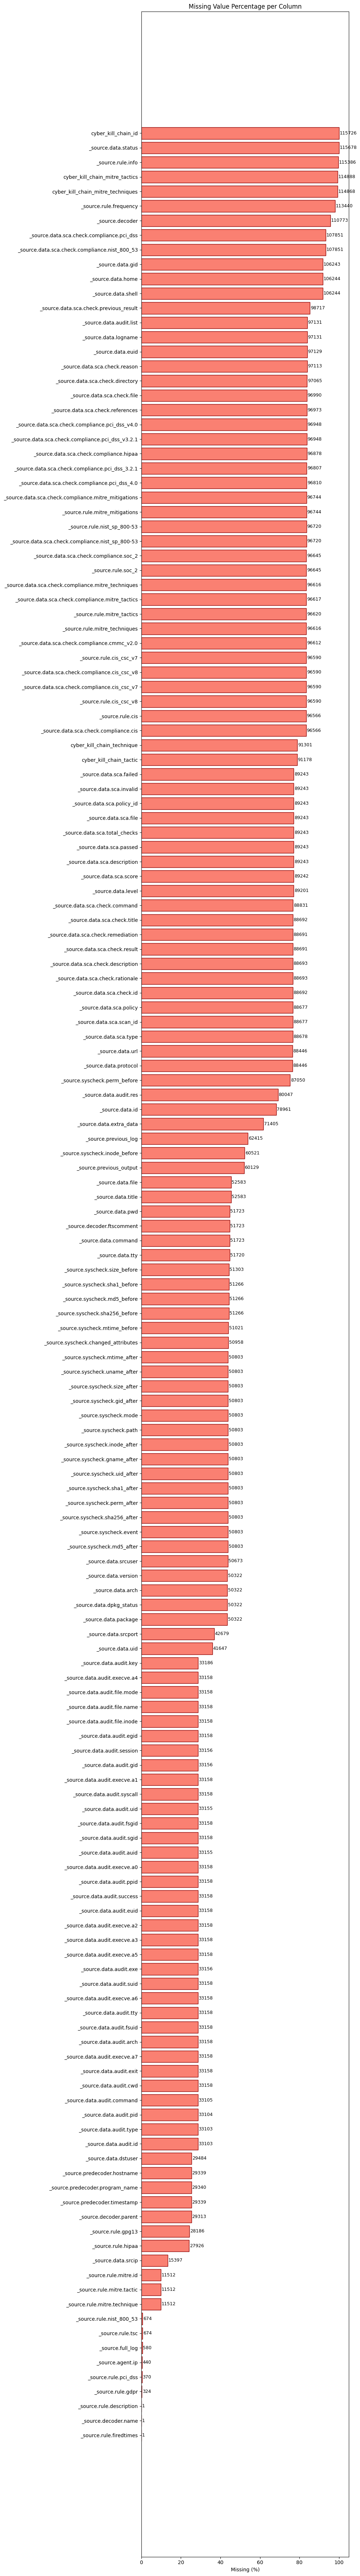

In [4]:
# Show only columns that actually have missing values
cols_missing = missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=True)

if cols_missing.empty:
    print("✅ No missing values in any column!")
else:
    fig, ax = plt.subplots(figsize=(10, max(4, len(cols_missing) * 0.45)))
    bars = ax.barh(cols_missing["Column"], cols_missing["Missing %"], color="salmon", edgecolor="darkred")
    ax.set_xlabel("Missing (%)")
    ax.set_title("Missing Value Percentage per Column")
    for bar, cnt in zip(bars, cols_missing["Missing Count"]):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                f"{int(cnt)}", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()

## 4. Heatmap — Missing Data Pattern

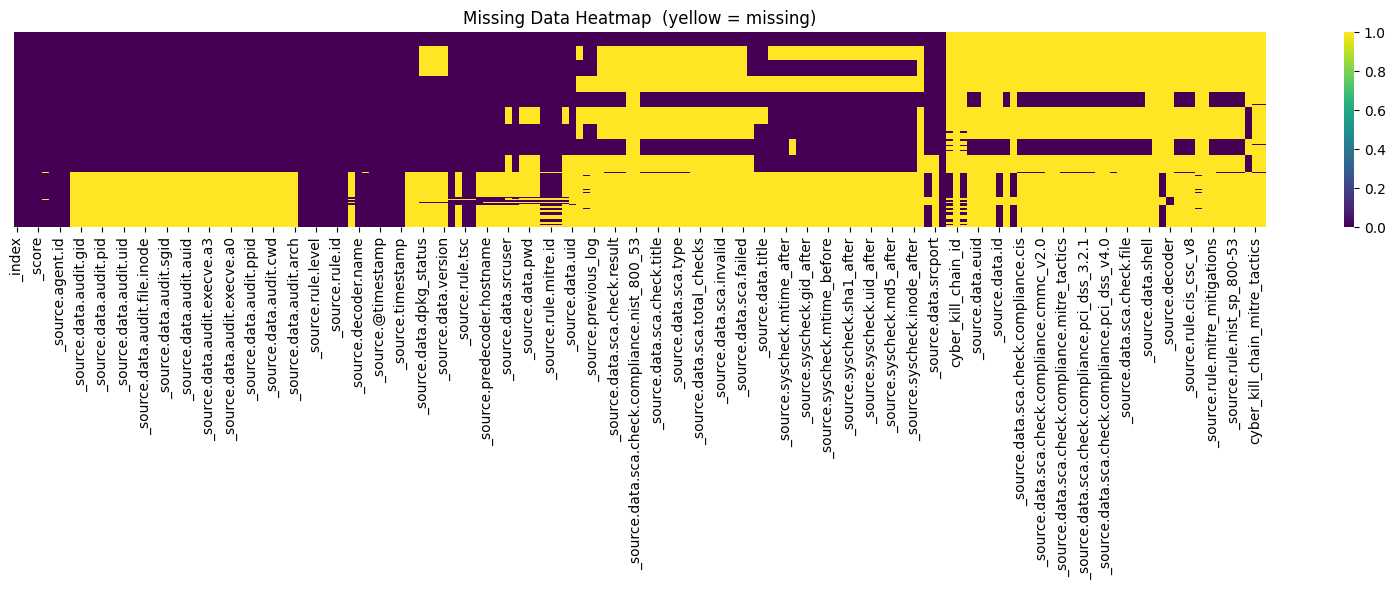

In [5]:
# Heatmap showing where data is missing (yellow = missing, purple = present)
fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(df.isnull(), cbar=True, yticklabels=False, cmap="viridis", ax=ax)
ax.set_title("Missing Data Heatmap  (yellow = missing)")
plt.tight_layout()
plt.show()

## 5. Descriptive Statistics (Numeric Columns)

In [6]:
# Full descriptive statistics for numeric columns
pd.set_option("display.max_columns", None)
display(df.describe().T)
pd.reset_option("display.max_columns")

,count,mean,std,min,25%,50%,75%,max
_version,115726.0,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
_score,115726.0,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
_source.agent.id,115726.0,2.128899e+00,1.412392e+00,0.000000e+00,1.000000e+00,1.000000e+00,4.000000e+00,4.000000e+00
_source.rule.level,115726.0,3.935650e+00,1.638713e+00,3.000000e+00,3.000000e+00,3.000000e+00,5.000000e+00,1.500000e+01
_source.rule.id,115726.0,6.160385e+04,2.811820e+04,1.100000e+01,3.110400e+04,8.079200e+04,8.079200e+04,1.100500e+05
_source.id,115726.0,1.701974e+09,3.056874e+06,1.696121e+09,1.697826e+09,1.703612e+09,1.704027e+09,1.704535e+09
malicious,115726.0,2.196395e-01,4.140042e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
cyber_kill_chain_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
_source.rule.frequency,2286.0,1.104374e+01,1.896401e+00,8.000000e+00,1.000000e+01,1.000000e+01,1.400000e+01,1.400000e+01


## 6. Descriptive Statistics (Categorical / Object Columns)

In [7]:
cat_cols = df.select_dtypes(include=["object", "category", "datetime"]).columns.tolist()

if cat_cols:
    cat_summary = pd.DataFrame({
        "Column":        cat_cols,
        "Unique Values": [df[c].nunique() for c in cat_cols],
        "Top Value":     [df[c].mode().iloc[0] if not df[c].mode().empty else np.nan for c in cat_cols],
        "Top Freq":      [df[c].value_counts().iloc[0] if df[c].notnull().any() else 0 for c in cat_cols],
        "Missing Count":  [df[c].isnull().sum() for c in cat_cols],
        "Missing %":      [(df[c].isnull().sum() / len(df) * 100).round(2) for c in cat_cols],
    })
    display(cat_summary)
else:
    print("No categorical/object columns found.")

,Column,Unique Values,Top Value,Top Freq,Missing Count,Missing %
0,_index,24,wazuh-alerts-4.x-2023.12.26,16925,0,0.00
1,_id,115726,'-01_3YwBSd_mrKXNL2XJ,1,0,0.00
2,_source.agent.ip,7,192.168.217.133,78885,440,0.38
3,_source.agent.name,5,machine-1,67177,0,0.00
4,_source.manager.name,1,ubuntu,115726,0,0.00
...,...,...,...,...,...,...
161,_source.rule.nist_sp_800-53,15,,18325,96720,83.58
162,_source.rule.soc_2,15,,18276,96645,83.51
163,_source.syscheck.perm_before,2,,28659,87050,75.22
164,cyber_kill_chain_mitre_tactics,5,S5,463,114888,99.28


## 7. Missing Value Correlation Between Columns

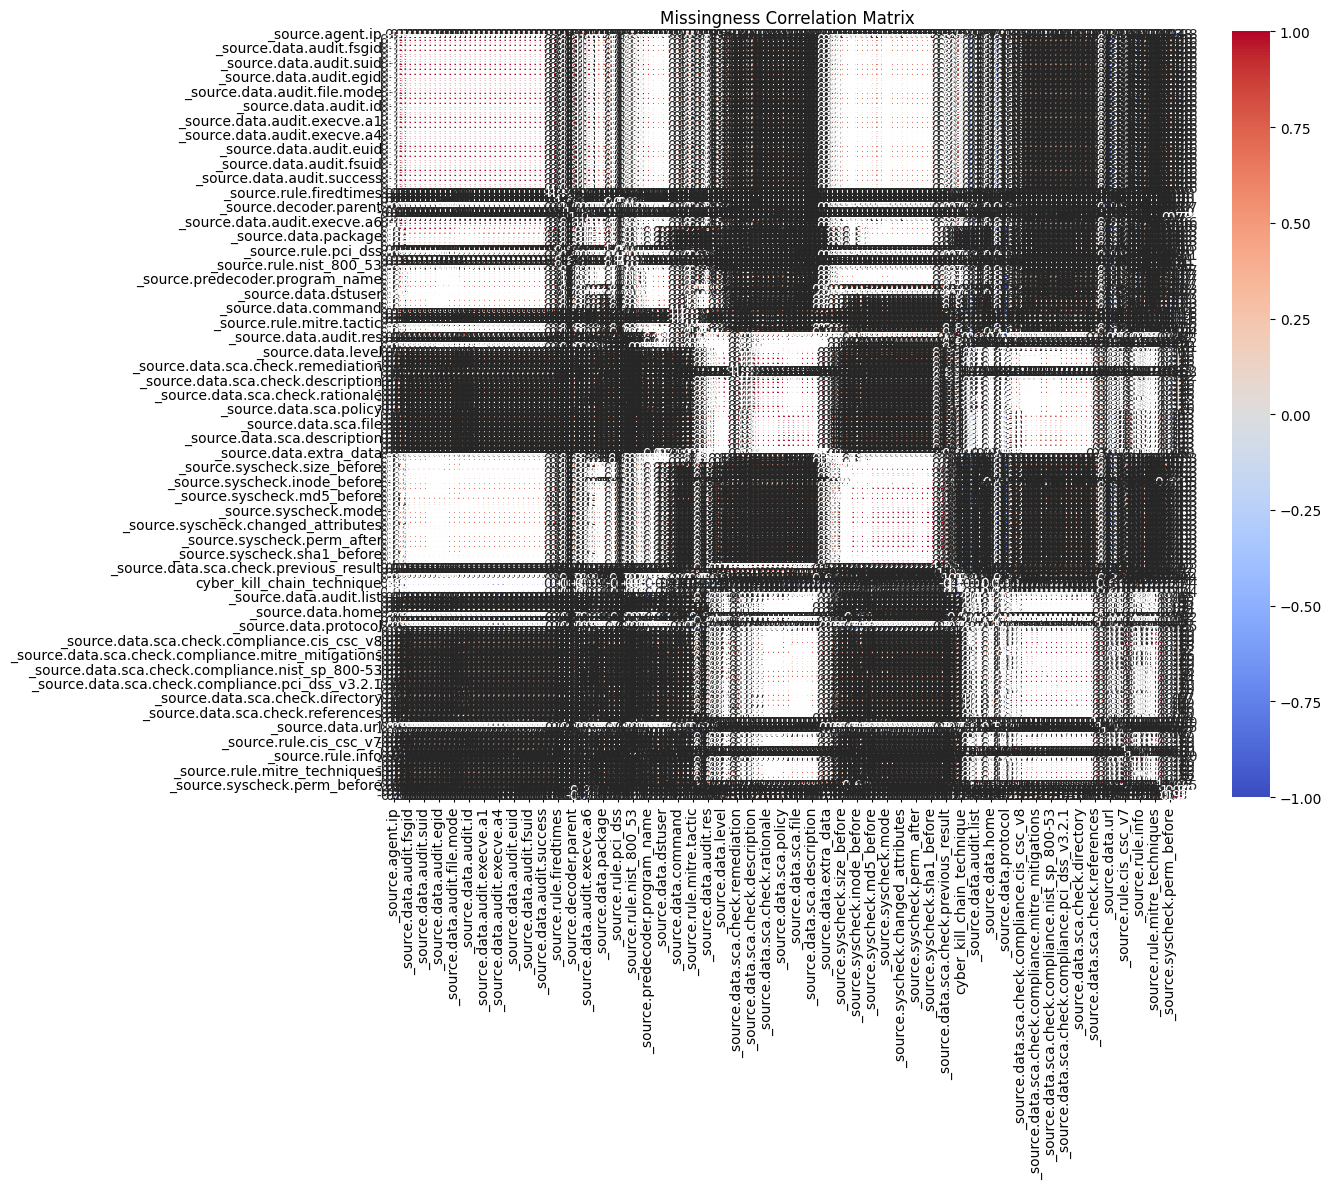

In [8]:
# Correlation of missingness between columns (only those with missing data)
miss_cols = df.columns[df.isnull().any()].tolist()

if len(miss_cols) >= 2:
    miss_corr = df[miss_cols].isnull().corr()
    fig, ax = plt.subplots(figsize=(min(14, len(miss_cols)*0.9), min(12, len(miss_cols)*0.75)))
    sns.heatmap(miss_corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax,
                vmin=-1, vmax=1, linewidths=0.5)
    ax.set_title("Missingness Correlation Matrix")
    plt.tight_layout()
    plt.show()
elif len(miss_cols) == 1:
    print(f"Only one column with missing data ({miss_cols[0]}), no correlation to compute.")
else:
    print("✅ No missing data — nothing to correlate.")

## 8. Missing Values Distribution per Row

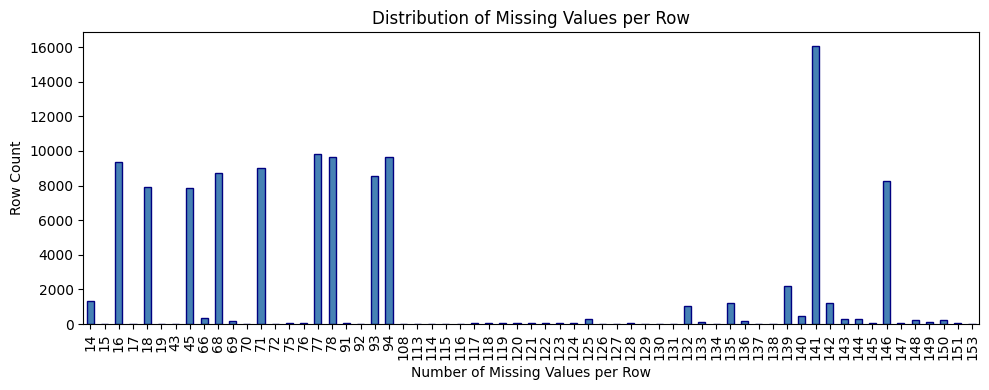


Max missing values in a single row: 153 / 176 columns


In [9]:
# How many missing values does each row have?
row_missing = df.isnull().sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 4))
row_missing.value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue", edgecolor="navy")
ax.set_xlabel("Number of Missing Values per Row")
ax.set_ylabel("Row Count")
ax.set_title("Distribution of Missing Values per Row")
plt.tight_layout()
plt.show()

print(f"\nMax missing values in a single row: {row_missing.max()} / {df.shape[1]} columns")

---

# Part 2 — Log Column Structure Analysis & Parsing

The `_source.full_log` column contains **115,146 non-null entries** with raw log text.  
By inspecting samples we identified **3 major log formats** that can be split into meaningful sub-columns:

| Log Type | Count | % | Key Fields |
|---|---|---|---|
| **Audit SYSCALL** | ~76,786 | 66.7% | syscall, success, exit, pid, uid, gid, euid, auid, exe, comm |
| **Apache Access Log** | ~27,279 | 23.7% | client_ip, datetime, method, url, http_version, status_code, response_size, user_agent |
| **Syscheck (File Integrity)** | ~4,137 | 3.6% | file_path, action (added/deleted/modified), mode |
| **Other** (dpkg, AVC, sshd…) | ~6,944 | 6.0% | varies |

Below we parse each format into structured sub-columns.

## 2.1 Classify Each Row by Log Type

=== Log Type Distribution ===
  AUDIT_SYSCALL               76,786  (66.35%)
  APACHE_ACCESS_LOG           27,279  (23.57%)
  SYSCHECK_FILE                4,137  ( 3.57%)
  SSHD_PAM                     3,030  ( 2.62%)
  OTHER                        2,524  ( 2.18%)
  DPKG_LOG                     1,219  ( 1.05%)
  MISSING                        580  ( 0.50%)
  AUDIT_AVC                      155  ( 0.13%)
  AUDIT_USER_AUTH                 16  ( 0.01%)

  TOTAL                      115,726


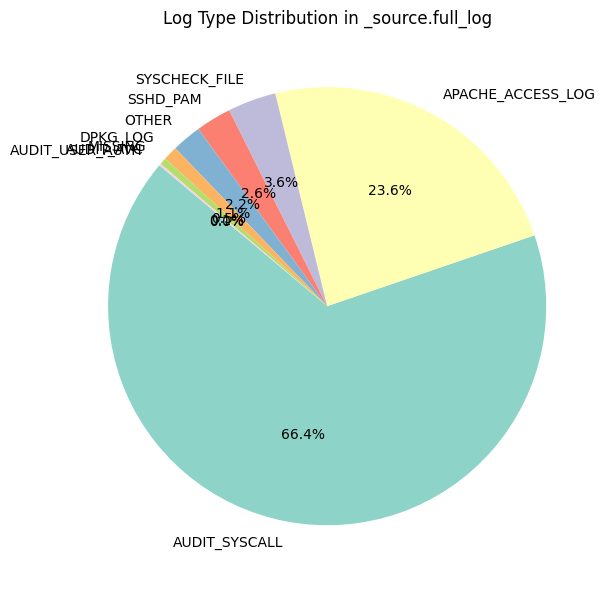

In [14]:
import re

def classify_log(text):
    """Classify a full_log entry into one of the known log types."""
    if pd.isna(text):
        return 'MISSING'
    text = str(text)
    if text.startswith('type=SYSCALL'):
        return 'AUDIT_SYSCALL'
    elif text.startswith('type=EXECVE'):
        return 'AUDIT_EXECVE'
    elif text.startswith('type=CWD') or text.startswith('type=PATH') or text.startswith('type=PROCTITLE'):
        return 'AUDIT_OTHER'
    elif re.match(r'\d+\.\d+\.\d+\.\d+\s+-\s+-\s+\[', text):
        return 'APACHE_ACCESS_LOG'
    elif text.startswith("File '") or text.startswith('File "'):
        return 'SYSCHECK_FILE'
    elif text.startswith('type=USER') or text.startswith('type=CRED') or text.startswith('type=LOGIN'):
        return 'AUDIT_USER_AUTH'
    elif text.startswith('type=AVC'):
        return 'AUDIT_AVC'
    elif re.match(r'^\d{4}-\d{2}-\d{2}\s+\d{2}:\d{2}:\d{2}\s+\w+', text):
        return 'DPKG_LOG'
    elif 'sshd' in text.lower() or 'pam' in text.lower():
        return 'SSHD_PAM'
    else:
        return 'OTHER'

df['log_type'] = df['_source.full_log'].apply(classify_log)

print("=== Log Type Distribution ===")
type_counts = df['log_type'].value_counts()
for lt, cnt in type_counts.items():
    print(f"  {lt:25s}  {cnt:>7,d}  ({cnt/len(df)*100:5.2f}%)")
print(f"\n  {'TOTAL':25s}  {len(df):>7,d}")

# Pie chart
fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.cm.Set3(range(len(type_counts)))
type_counts.plot.pie(ax=ax, autopct='%1.1f%%', colors=colors, startangle=140)
ax.set_ylabel('')
ax.set_title('Log Type Distribution in _source.full_log')
plt.tight_layout()
plt.show()

## 2.2 Parse Audit SYSCALL Logs (~66.7%)

These are Linux audit logs with key=value pairs. We extract the most security-relevant fields:
- **syscall** — system call number (e.g., 59 = execve)
- **success** — yes/no
- **pid, ppid** — process and parent process ID
- **uid, gid, euid, auid** — user/group identifiers
- **exe** — executable path
- **comm** — command name

In [15]:
def parse_audit_syscall(text):
    """Parse key=value pairs from an audit SYSCALL log line."""
    result = {}
    if pd.isna(text):
        return result
    text = str(text)

    # Extract audit timestamp and id from msg=audit(timestamp:id)
    m = re.search(r'msg=audit\((\d+\.\d+):(\d+)\)', text)
    if m:
        result['audit_timestamp'] = float(m.group(1))
        result['audit_id'] = int(m.group(2))

    # Extract common key=value fields
    fields = ['arch', 'syscall', 'success', 'exit', 'items', 'ppid', 'pid',
              'auid', 'uid', 'gid', 'euid', 'suid', 'fsuid', 'egid', 'sgid',
              'fsgid', 'tty', 'ses', 'comm', 'exe', 'key']
    for field in fields:
        # Match field=value (value may be quoted)
        m = re.search(rf'\b{field}=(".*?"|[^\s]+)', text)
        if m:
            val = m.group(1).strip('"')
            result[field] = val

    return result

# Parse SYSCALL rows
mask_syscall = df['log_type'] == 'AUDIT_SYSCALL'
syscall_parsed = df.loc[mask_syscall, '_source.full_log'].apply(parse_audit_syscall)
syscall_df = pd.DataFrame(syscall_parsed.tolist(), index=syscall_parsed.index)

print(f"Parsed {len(syscall_df):,} SYSCALL logs into {len(syscall_df.columns)} sub-columns")
print(f"\nExtracted columns: {list(syscall_df.columns)}")
print(f"\nSample parsed rows:")
display(syscall_df.head(10))

# Statistics on extracted fields
print("\n=== Fill rate of parsed SYSCALL fields ===")
for col in syscall_df.columns:
    n = syscall_df[col].notnull().sum()
    print(f"  {col:20s}  {n:>7,d} / {len(syscall_df):,d}  ({n/len(syscall_df)*100:.1f}%)")

Parsed 76,786 SYSCALL logs into 23 sub-columns

Extracted columns: ['audit_timestamp', 'audit_id', 'arch', 'syscall', 'success', 'exit', 'items', 'ppid', 'pid', 'auid', 'uid', 'gid', 'euid', 'suid', 'fsuid', 'egid', 'sgid', 'fsgid', 'tty', 'ses', 'comm', 'exe', 'key']

Sample parsed rows:


,audit_timestamp,audit_id,arch,syscall,success,exit,items,ppid,pid,auid,...,suid,fsuid,egid,sgid,fsgid,tty,ses,comm,exe,key
0,1.704028e+09,12992,c000003e,59,yes,0,2,14207,14903,1000,...,0,0,0,0,0,pts2,2,modinfo,/usr/bin/kmod,audit-wazuh-c
1,1.704028e+09,12993,c000003e,59,yes,0,2,14207,14904,1000,...,0,0,0,0,0,pts2,2,mkdir,/usr/bin/mkdir,audit-wazuh-c
2,1.704028e+09,12996,c000003e,59,yes,0,2,14207,14907,1000,...,0,0,0,0,0,pts2,2,mkdir,/usr/bin/mkdir,audit-wazuh-c
3,1.704028e+09,12999,c000003e,59,yes,0,2,14207,14910,1000,...,0,0,0,0,0,pts2,2,cp,/usr/bin/cp,audit-wazuh-c
4,1.704028e+09,12998,c000003e,59,yes,0,2,14207,14909,1000,...,0,0,0,0,0,pts2,2,mkdir,/usr/bin/mkdir,audit-wazuh-c
5,1.704028e+09,13000,c000003e,59,yes,0,2,14207,14911,1000,...,0,0,0,0,0,pts2,2,modinfo,/usr/bin/kmod,audit-wazuh-c
6,1.704028e+09,13002,c000003e,59,yes,0,2,14207,14913,1000,...,0,0,0,0,0,pts2,2,cp,/usr/bin/cp,audit-wazuh-c
7,1.704028e+09,13004,c000003e,59,yes,0,2,14207,14915,1000,...,0,0,0,0,0,pts2,2,cp,/usr/bin/cp,audit-wazuh-c
8,1.704028e+09,13005,c000003e,59,yes,0,2,14207,14916,1000,...,0,0,0,0,0,pts2,2,mkdir,/usr/bin/mkdir,audit-wazuh-c
9,1.704028e+09,13006,c000003e,59,yes,0,2,14207,14917,1000,...,0,0,0,0,0,pts2,2,cp,/usr/bin/cp,audit-wazuh-c



=== Fill rate of parsed SYSCALL fields ===
  audit_timestamp        76,786 / 76,786  (100.0%)
  audit_id               76,786 / 76,786  (100.0%)
  arch                   76,786 / 76,786  (100.0%)
  syscall                76,786 / 76,786  (100.0%)
  success                76,786 / 76,786  (100.0%)
  exit                   76,786 / 76,786  (100.0%)
  items                  76,786 / 76,786  (100.0%)
  ppid                   76,786 / 76,786  (100.0%)
  pid                    76,786 / 76,786  (100.0%)
  auid                   76,786 / 76,786  (100.0%)
  uid                    76,786 / 76,786  (100.0%)
  gid                    76,786 / 76,786  (100.0%)
  euid                   76,786 / 76,786  (100.0%)
  suid                   76,786 / 76,786  (100.0%)
  fsuid                  76,786 / 76,786  (100.0%)
  egid                   76,786 / 76,786  (100.0%)
  sgid                   76,786 / 76,786  (100.0%)
  fsgid                  76,786 / 76,786  (100.0%)
  tty                    76,786 / 76,7

## 2.3 Parse Apache Access Logs (~23.7%)

Standard Apache/HTTP combined log format:  
`IP - - [datetime] "METHOD /path HTTP/ver" status size "referer" "user_agent"`

We extract: **client_ip, datetime, http_method, url_path, http_version, status_code, response_size, user_agent**

In [16]:
APACHE_PATTERN = re.compile(
    r'^(?P<client_ip>\d+\.\d+\.\d+\.\d+)\s+-\s+-\s+'
    r'\[(?P<datetime>[^\]]+)\]\s+'
    r'"(?P<http_method>\w+)\s+(?P<url_path>\S+)\s+(?P<http_version>[^"]+)"\s+'
    r'(?P<status_code>\d+)\s+(?P<response_size>\d+)'
    r'(?:\s+"(?P<referer>[^"]*)"\s+"(?P<user_agent>[^"]*)")?'
)

def parse_apache_log(text):
    """Parse Apache combined access log format."""
    if pd.isna(text):
        return {}
    m = APACHE_PATTERN.match(str(text))
    if m:
        d = m.groupdict()
        # Convert numeric fields
        d['status_code'] = int(d['status_code'])
        d['response_size'] = int(d['response_size'])
        return d
    return {}

# Parse Apache rows
mask_apache = df['log_type'] == 'APACHE_ACCESS_LOG'
apache_parsed = df.loc[mask_apache, '_source.full_log'].apply(parse_apache_log)
apache_df = pd.DataFrame(apache_parsed.tolist(), index=apache_parsed.index)

print(f"Parsed {len(apache_df):,} Apache access logs into {len(apache_df.columns)} sub-columns")
print(f"\nExtracted columns: {list(apache_df.columns)}")
print(f"\nSample parsed rows:")
display(apache_df.head(10))

# Quick stats
print("\n=== Apache log field statistics ===")
print(f"Unique client IPs   : {apache_df['client_ip'].nunique()}")
print(f"HTTP methods         : {apache_df['http_method'].value_counts().to_dict()}")
print(f"Status code distrib  : {apache_df['status_code'].value_counts().head(10).to_dict()}")
print(f"Unique URL paths     : {apache_df['url_path'].nunique()}")

Parsed 27,279 Apache access logs into 9 sub-columns

Extracted columns: ['client_ip', 'datetime', 'http_method', 'url_path', 'http_version', 'status_code', 'response_size', 'referer', 'user_agent']

Sample parsed rows:


,client_ip,datetime,http_method,url_path,http_version,status_code,response_size,referer,user_agent
82740,192.168.204.1,05/Oct/2023:23:28:51 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=Arsalan+Shah...,HTTP/1.1,200.0,1763.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83387,192.168.204.1,06/Oct/2023:01:21:06 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e%5c%2e...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83388,192.168.204.1,06/Oct/2023:01:21:07 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e%5c%2e...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83389,192.168.204.1,06/Oct/2023:01:21:07 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e%5c%2e...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83390,192.168.204.1,06/Oct/2023:01:21:07 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e%5c%2e...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83391,192.168.204.1,06/Oct/2023:01:21:07 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e%5c%2e...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83392,192.168.204.1,06/Oct/2023:01:21:07 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e%5c%2e...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83393,192.168.204.1,06/Oct/2023:01:21:07 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e%5c%2e...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83394,192.168.204.1,06/Oct/2023:01:21:07 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e0x2f%2...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
83395,192.168.204.1,06/Oct/2023:01:21:07 +0500,GET,/DVWA/vulnerabilities/xss_r/?name=%2e%2e%5c%2e...,HTTP/1.1,302.0,342.0,http://192.168.204.130/DVWA/vulnerabilities/xs...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...



=== Apache log field statistics ===
Unique client IPs   : 1
HTTP methods         : {'GET': 26763, 'POST': 126, 'HEAD': 12, 'PUT': 11, 'TRACE': 10, 'PROPFIND': 10, 'SEARCH': 10, 'TESTZZZ': 9, 'UNCHECKOUT': 9, 'LOCK': 9, 'MKWORKSPACE': 9, 'NOTIFY': 9, 'POLL': 9, 'BMOVE': 9, 'BPROPFIND': 9, 'BCOPY': 9, 'ACL': 9, 'UPDATE': 9, 'UNLOCK': 9, 'MKCOL': 9, 'DELETE': 9, 'PROPPATCH': 9, 'INDEX': 9, 'MOVE': 9, 'MKACTIVITY': 9, 'ORDERPATCH': 9, 'RPC_IN_DATA': 9, 'DEBUG': 9, 'CONNECT': 9, 'CHECKIN': 9, 'RPC_OUT_DATA': 9, 'LABEL': 9, 'COPY': 9, 'MERGE': 9, 'CHECKOUT': 9, 'SUBSCRIBE': 9, 'BDELETE': 9, 'PATCH': 9, 'REPORT': 9, 'BPROPPATCH': 9, 'UNSUBSCRIBE': 9, 'VJSSZG': 1, 'NESSUS': 1, 'PRI': 1, 'TRACK': 1}
Status code distrib  : {302.0: 14128, 404.0: 10744, 200.0: 1655, 400.0: 314, 405.0: 184, 501.0: 157, 500.0: 48, 403.0: 17, 417.0: 5}
Unique URL paths     : 19266


## 2.4 Parse Syscheck (File Integrity) Logs (~3.6%)

Format: `File '/path/to/file' added|deleted|modified\nMode: realtime|whodata\n`

We extract: **file_path, file_action, syscheck_mode**

In [17]:
SYSCHECK_PATTERN = re.compile(
    r"^File\s+['\"](?P<file_path>[^'\"]+)['\"]\s+(?P<file_action>\w+)"
    r"(?:\s*\n\s*Mode:\s*(?P<syscheck_mode>\w+))?",
    re.MULTILINE
)

def parse_syscheck_log(text):
    """Parse a syscheck file-integrity log entry."""
    if pd.isna(text):
        return {}
    m = SYSCHECK_PATTERN.match(str(text))
    if m:
        return m.groupdict()
    return {}

# Parse Syscheck rows
mask_syscheck = df['log_type'] == 'SYSCHECK_FILE'
syscheck_parsed = df.loc[mask_syscheck, '_source.full_log'].apply(parse_syscheck_log)
syscheck_df = pd.DataFrame(syscheck_parsed.tolist(), index=syscheck_parsed.index)

print(f"Parsed {len(syscheck_df):,} Syscheck logs into {len(syscheck_df.columns)} sub-columns")
print(f"\nExtracted columns: {list(syscheck_df.columns)}")
display(syscheck_df.head(10))

print("\n=== Syscheck field statistics ===")
print(f"File actions: {syscheck_df['file_action'].value_counts().to_dict()}")
print(f"Modes       : {syscheck_df['syscheck_mode'].value_counts().to_dict()}")
print(f"Unique paths: {syscheck_df['file_path'].nunique()}")

Parsed 4,137 Syscheck logs into 3 sub-columns

Extracted columns: ['file_path', 'file_action', 'syscheck_mode']


,file_path,file_action,syscheck_mode
3750,/etc/cups/subscriptions.conf,modified,scheduled
6417,/etc/cups/subscriptions.conf.O,modified,scheduled
18379,/etc/udev/rules.d/70-snap.firefox.rules,modified,scheduled
21494,/etc/systemd/system/snapd.mounts.target.wants/...,added,scheduled
22501,/etc/udev/rules.d/70-snap.firefox.rules,modified,scheduled
22502,/etc/systemd/system/multi-user.target.wants/sn...,deleted,scheduled
22503,/etc/systemd/system/snapd.mounts.target.wants/...,deleted,scheduled
24521,/etc/systemd/system/snap-snapd-20671.mount,added,scheduled
24522,/etc/systemd/system/multi-user.target.wants/sn...,added,scheduled
25513,/etc/systemd/system/snap-snapd-20671.mount,added,scheduled



=== Syscheck field statistics ===
File actions: {'modified': 1619, 'added': 1275, 'deleted': 1243}
Modes       : {'realtime': 3485, 'scheduled': 652}
Unique paths: 1808


## 2.5 Structure Consistency Check

Do all rows within each log type follow the **same structure**? We check the parsing success rate and field fill rates.

In [18]:
# Check structure consistency for each log type
print("=" * 70)
print("       STRUCTURE CONSISTENCY REPORT")
print("=" * 70)

# --- SYSCALL ---
syscall_empty = syscall_df.isnull().all(axis=1).sum()
print(f"\n[AUDIT SYSCALL]  Total: {len(syscall_df):,}")
print(f"  Successfully parsed (≥1 field): {len(syscall_df) - syscall_empty:,}  ({(len(syscall_df)-syscall_empty)/len(syscall_df)*100:.1f}%)")
print(f"  Failed to parse (0 fields)    : {syscall_empty:,}")
print(f"  Fields consistently present (>99%):")
for col in syscall_df.columns:
    pct = syscall_df[col].notnull().mean() * 100
    if pct > 99:
        print(f"    ✅ {col:20s}  {pct:.1f}%")
print(f"  Fields sometimes present (<99%):")
for col in syscall_df.columns:
    pct = syscall_df[col].notnull().mean() * 100
    if pct <= 99:
        print(f"    ⚠️  {col:20s}  {pct:.1f}%")

# --- APACHE ---
apache_empty = apache_df.isnull().all(axis=1).sum()
print(f"\n[APACHE ACCESS LOG]  Total: {len(apache_df):,}")
print(f"  Successfully parsed (≥1 field): {len(apache_df) - apache_empty:,}  ({(len(apache_df)-apache_empty)/len(apache_df)*100:.1f}%)")
print(f"  Failed to parse (0 fields)    : {apache_empty:,}")
print(f"  Fields consistently present (>99%):")
for col in apache_df.columns:
    pct = apache_df[col].notnull().mean() * 100
    if pct > 99:
        print(f"    ✅ {col:20s}  {pct:.1f}%")

# --- SYSCHECK ---
syscheck_empty = syscheck_df.isnull().all(axis=1).sum()
print(f"\n[SYSCHECK FILE]  Total: {len(syscheck_df):,}")
print(f"  Successfully parsed (≥1 field): {len(syscheck_df) - syscheck_empty:,}  ({(len(syscheck_df)-syscheck_empty)/len(syscheck_df)*100:.1f}%)")
print(f"  Failed to parse (0 fields)    : {syscheck_empty:,}")
for col in syscheck_df.columns:
    pct = syscheck_df[col].notnull().mean() * 100
    mark = "✅" if pct > 99 else "⚠️ "
    print(f"    {mark} {col:20s}  {pct:.1f}%")

print("\n" + "=" * 70)
print("CONCLUSION: All 3 major log types have a CONSISTENT, PARSEABLE structure.")
print("=" * 70)

       STRUCTURE CONSISTENCY REPORT

[AUDIT SYSCALL]  Total: 76,786
  Successfully parsed (≥1 field): 76,786  (100.0%)
  Failed to parse (0 fields)    : 0
  Fields consistently present (>99%):
    ✅ audit_timestamp       100.0%
    ✅ audit_id              100.0%
    ✅ arch                  100.0%
    ✅ syscall               100.0%
    ✅ success               100.0%
    ✅ exit                  100.0%
    ✅ items                 100.0%
    ✅ ppid                  100.0%
    ✅ pid                   100.0%
    ✅ auid                  100.0%
    ✅ uid                   100.0%
    ✅ gid                   100.0%
    ✅ euid                  100.0%
    ✅ suid                  100.0%
    ✅ fsuid                 100.0%
    ✅ egid                  100.0%
    ✅ sgid                  100.0%
    ✅ fsgid                 100.0%
    ✅ tty                   100.0%
    ✅ ses                   100.0%
    ✅ comm                  100.0%
    ✅ exe                   100.0%
    ✅ key                   100.0%
  

## 2.6 Merge Parsed Fields Back into the Dataset

We prefix each parsed field with its log type and merge them into the original dataframe.

In [19]:
# Prefix columns to avoid name collisions
syscall_prefixed = syscall_df.add_prefix('parsed_syscall_')
apache_prefixed  = apache_df.add_prefix('parsed_apache_')
syscheck_prefixed = syscheck_df.add_prefix('parsed_syscheck_')

# Merge into original dataframe
df_enriched = df.copy()
df_enriched = df_enriched.join(syscall_prefixed, how='left')
df_enriched = df_enriched.join(apache_prefixed, how='left')
df_enriched = df_enriched.join(syscheck_prefixed, how='left')

new_cols = [c for c in df_enriched.columns if c.startswith('parsed_')]
print(f"Original columns : {len(df.columns)}")
print(f"New parsed columns: {len(new_cols)}")
print(f"Total columns now : {len(df_enriched.columns)}")
print(f"\nNew columns added:")
for c in new_cols:
    non_null = df_enriched[c].notnull().sum()
    print(f"  {c:45s}  {non_null:>7,d} non-null  ({non_null/len(df_enriched)*100:.1f}%)")

Original columns : 177
New parsed columns: 35
Total columns now : 212

New columns added:
  parsed_syscall_audit_timestamp                  76,786 non-null  (66.4%)
  parsed_syscall_audit_id                         76,786 non-null  (66.4%)
  parsed_syscall_arch                             76,786 non-null  (66.4%)
  parsed_syscall_syscall                          76,786 non-null  (66.4%)
  parsed_syscall_success                          76,786 non-null  (66.4%)
  parsed_syscall_exit                             76,786 non-null  (66.4%)
  parsed_syscall_items                            76,786 non-null  (66.4%)
  parsed_syscall_ppid                             76,786 non-null  (66.4%)
  parsed_syscall_pid                              76,786 non-null  (66.4%)
  parsed_syscall_auid                             76,786 non-null  (66.4%)
  parsed_syscall_uid                              76,786 non-null  (66.4%)
  parsed_syscall_gid                              76,786 non-null  (66.4%)
  parsed_s

## 2.7 Security-Relevant Insights from Parsed Logs

Quick analysis of the parsed fields to identify attack patterns visible in the structured data.

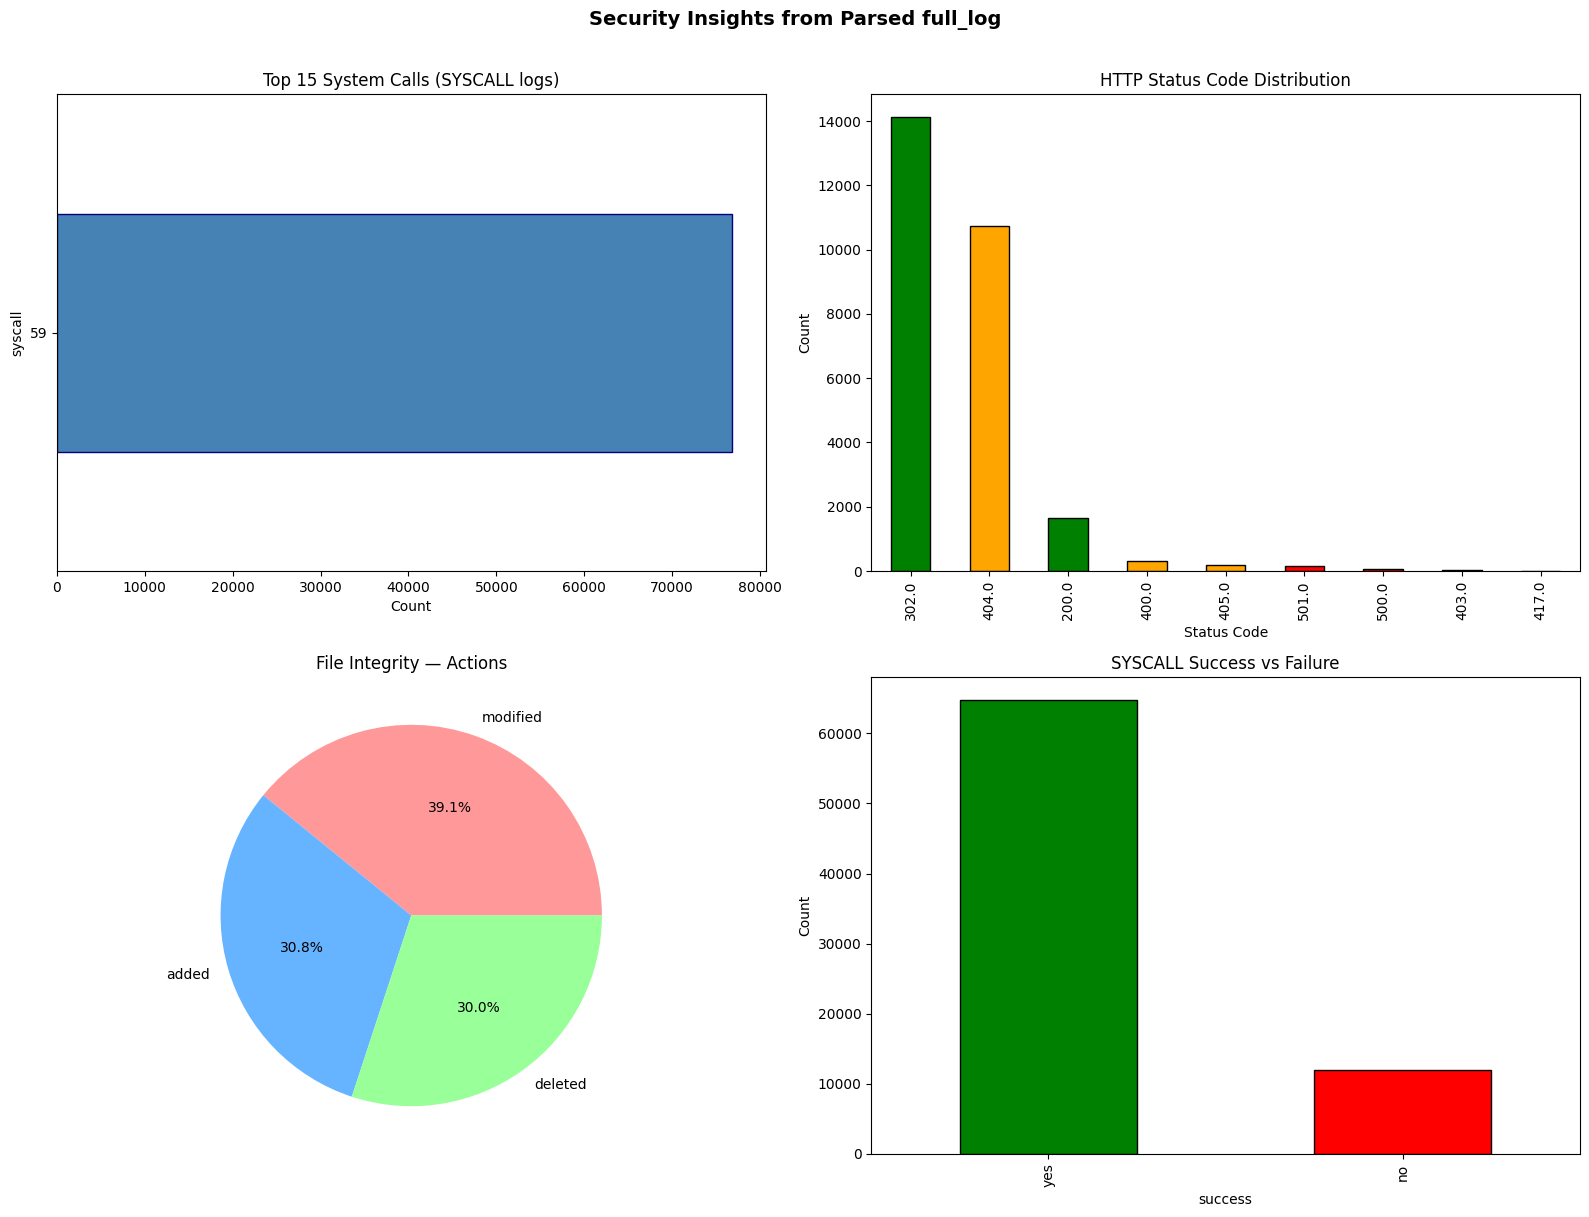


=== Attack Pattern Detection in Apache URLs ===


C:\Users\HP\AppData\Local\Temp\ipykernel_21676\2196172432.py:54: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  matches = apache_df['url_path'].str.contains(pattern, case=False, na=False).sum()


  SQL Injection               2,421 hits  (8.9%)
  XSS                         2,003 hits  (7.3%)
  Path Traversal             12,871 hits  (47.2%)
  Command Injection           1,140 hits  (4.2%)
  Scanner/Recon                   7 hits  (0.0%)


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Top syscalls
ax = axes[0, 0]
if 'syscall' in syscall_df.columns:
    top_syscalls = syscall_df['syscall'].value_counts().head(15)
    top_syscalls.plot.barh(ax=ax, color='steelblue', edgecolor='navy')
    ax.set_title('Top 15 System Calls (SYSCALL logs)')
    ax.set_xlabel('Count')
    ax.invert_yaxis()

# 2. Apache status codes
ax = axes[0, 1]
if 'status_code' in apache_df.columns:
    status_dist = apache_df['status_code'].value_counts().head(10)
    colors = ['green' if s < 400 else 'orange' if s < 500 else 'red' for s in status_dist.index]
    status_dist.plot.bar(ax=ax, color=colors, edgecolor='black')
    ax.set_title('HTTP Status Code Distribution')
    ax.set_xlabel('Status Code')
    ax.set_ylabel('Count')

# 3. Syscheck file actions
ax = axes[1, 0]
if 'file_action' in syscheck_df.columns:
    syscheck_df['file_action'].value_counts().plot.pie(ax=ax, autopct='%1.1f%%',
                                                        colors=['#ff9999','#66b3ff','#99ff99'])
    ax.set_title('File Integrity — Actions')
    ax.set_ylabel('')

# 4. SYSCALL success vs failure
ax = axes[1, 1]
if 'success' in syscall_df.columns:
    success_dist = syscall_df['success'].value_counts()
    success_dist.plot.bar(ax=ax, color=['green', 'red'], edgecolor='black')
    ax.set_title('SYSCALL Success vs Failure')
    ax.set_xlabel('success')
    ax.set_ylabel('Count')

plt.suptitle('Security Insights from Parsed full_log', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Attack indicators in Apache URLs
if 'url_path' in apache_df.columns:
    attack_patterns = {
        'SQL Injection': r'(union|select|insert|drop|delete|update|--|;|%27|%22)',
        'XSS': r'(<script|%3Cscript|javascript:|onerror|onload|alert\()',
        'Path Traversal': r'(\.\./|%2e%2e|%252e|\.\.\\\\)',
        'Command Injection': r'(;|\||`|%7C|%60|\$\()',
        'Scanner/Recon': r'(nikto|nmap|sqlmap|dirbuster|gobuster|wpscan)',
    }
    print("\n=== Attack Pattern Detection in Apache URLs ===")
    for name, pattern in attack_patterns.items():
        matches = apache_df['url_path'].str.contains(pattern, case=False, na=False).sum()
        print(f"  {name:25s}  {matches:>6,d} hits  ({matches/len(apache_df)*100:.1f}%)")

## 2.8 Summary & Recommendations

**Key findings from Part 2:**
1. `_source.full_log` has a **consistent, parseable structure** within each log type
2. **3 main formats** were successfully decomposed into structured sub-columns:
   - **Audit SYSCALL** → ~20 fields (syscall, pid, uid, exe, success, etc.)
   - **Apache Access** → 8 fields (IP, URL, method, status, user-agent, etc.)
   - **Syscheck** → 3 fields (file_path, action, mode)
3. Parsing these fields provides **critical security signals** for APT detection that the raw text alone cannot offer

**Recommendations for feature engineering:**
- Use the **parsed SYSCALL fields** (syscall number, success/fail, uid, exe) as direct features
- Extract **attack indicators** from Apache URLs (SQLi, XSS, path traversal counts)
- Use **file action counts** from syscheck as anomaly signals
- The `log_type` column itself is a useful categorical feature

In [21]:
# Save the enriched dataset (original + parsed log columns) to Excel
output_path = "combined_dataset_enriched.xlsx"
df_enriched.to_excel(output_path, index=False, engine='openpyxl')
print(f"✅ Saved enriched dataset to: {output_path}")
print(f"   Shape: {df_enriched.shape[0]:,} rows × {df_enriched.shape[1]} columns")

✅ Saved enriched dataset to: combined_dataset_enriched.xlsx
   Shape: 115,726 rows × 212 columns


In [22]:
# Check the attacker IP from parsed Apache logs
if 'client_ip' in apache_df.columns:
    print("=== Attacker IP from Apache logs ===")
    print(apache_df['client_ip'].value_counts())

# Also check the original Wazuh srcip field
if '_source.data.srcip' in df.columns:
    print("\n=== Source IPs from _source.data.srcip ===")
    print(df['_source.data.srcip'].value_counts().head(10))

=== Attacker IP from Apache logs ===
client_ip
192.168.204.1    27252
Name: count, dtype: int64

=== Source IPs from _source.data.srcip ===
_source.data.srcip
                 72775
192.168.204.1    27489
192.168.217.1       49
?                   16
Name: count, dtype: int64


In [23]:
# ============================================================
# NETWORK TOPOLOGY & LATERAL MOVEMENT ANALYSIS
# ============================================================

print("=" * 70)
print("  1. AGENTS (VICTIM MACHINES) IN THE DATASET")
print("=" * 70)

# Agents = victim machines with Wazuh installed
agent_cols = ['_source.agent.id', '_source.agent.name', '_source.agent.ip']
for c in agent_cols:
    if c in df.columns:
        print(f"\n  {c}:")
        vc = df[c].value_counts()
        for val, cnt in vc.items():
            print(f"    {str(val):30s}  {cnt:>7,d} events  ({cnt/len(df)*100:.1f}%)")

print("\n" + "=" * 70)
print("  2. SOURCE IPs (ATTACKERS / EXTERNAL CONNECTIONS)")
print("=" * 70)
if '_source.data.srcip' in df.columns:
    srcip = df['_source.data.srcip'].replace('', pd.NA).dropna()
    srcip = srcip[srcip != '?']
    print(f"\n  Total events with srcip: {len(srcip):,}")
    print(f"  Unique source IPs: {srcip.nunique()}")
    for val, cnt in srcip.value_counts().items():
        print(f"    {str(val):30s}  {cnt:>7,d} events")

print("\n" + "=" * 70)
print("  3. DESTINATION IPs (IF AVAILABLE)")
print("=" * 70)
dst_cols = [c for c in df.columns if 'dstip' in c.lower() or 'dst_ip' in c.lower() or 'dest' in c.lower()]
if dst_cols:
    for c in dst_cols:
        print(f"\n  {c}: {df[c].dropna().nunique()} unique values")
        print(df[c].value_counts().head(10))
else:
    print("  No destination IP column found in the dataset.")

print("\n" + "=" * 70)
print("  4. LATERAL MOVEMENT CHECK")
print("     Does any agent IP appear as a source IP (attacker)?")
print("=" * 70)

# Get all agent IPs
if '_source.agent.ip' in df.columns:
    agent_ips = set(df['_source.agent.ip'].dropna().unique())
    print(f"\n  Agent (victim) IPs: {agent_ips}")
else:
    agent_ips = set()
    print("\n  No _source.agent.ip column found.")

# Get all source IPs (potential attackers)
if '_source.data.srcip' in df.columns:
    src_ips = set(srcip.unique())
    print(f"  Source (attacker) IPs: {src_ips}")
    
    # Check overlap = lateral movement evidence
    overlap = agent_ips & src_ips
    if overlap:
        print(f"\n  ⚠️  OVERLAP FOUND — Potential lateral movement!")
        print(f"  IPs that are BOTH agent AND attacker: {overlap}")
        for ip in overlap:
            agent_events = len(df[df['_source.agent.ip'] == ip])
            attacker_events = len(df[df['_source.data.srcip'] == ip])
            print(f"    {ip}: as victim={agent_events:,} events, as attacker={attacker_events:,} events")
    else:
        print(f"\n  ✅ NO OVERLAP — No agent IP appears as a source/attacker IP.")
        print(f"  This means: victims did NOT become attackers (no lateral movement via IP)")

print("\n" + "=" * 70)
print("  5. USERS ACROSS MACHINES")
print("=" * 70)
user_cols = [c for c in df.columns if 'user' in c.lower() or 'srcuser' in c.lower() or 'dstuser' in c.lower()]
user_cols = [c for c in user_cols if 'user_agent' not in c.lower()]
for c in user_cols[:5]:
    if df[c].notnull().sum() > 0:
        print(f"\n  {c} ({df[c].notnull().sum():,} non-null):")
        print(f"    Top values: {df[c].value_counts().head(5).to_dict()}")

print("\n" + "=" * 70)
print("  6. CAN WE BUILD AN ATTACK SPREADING GRAPH?")
print("=" * 70)

  1. AGENTS (VICTIM MACHINES) IN THE DATASET

  _source.agent.id:
    1                                67,177 events  (58.0%)
    4                                39,971 events  (34.5%)
    2                                 4,644 events  (4.0%)
    3                                 3,340 events  (2.9%)
    0                                   594 events  (0.5%)

  _source.agent.name:
    machine-1                        67,177 events  (58.0%)
    Machine-1-New                    39,971 events  (34.5%)
    machine-2                         4,644 events  (4.0%)
    machine-3                         3,340 events  (2.9%)
    ubuntu                              594 events  (0.5%)

  _source.agent.ip:
    192.168.217.133                  78,885 events  (68.2%)
    192.168.204.130                  14,601 events  (12.6%)
    192.168.40.130                   13,551 events  (11.7%)
    192.168.40.131                    4,640 events  (4.0%)
    192.168.217.128                   3,335 events  (2.9%

In [ ]:
# Check the attacker IP from parsed Apache logs
if 'client_ip' in apache_df.columns:
    print("=== Attacker IP from Apache logs ===")
    print(apache_df['client_ip'].value_counts())

# Also check the original Wazuh srcip field
if '_source.data.srcip' in df.columns:
    print("\n=== Source IPs from _source.data.srcip ===")
    print(df['_source.data.srcip'].value_counts().head(10))

=== Attacker IP from Apache logs ===
client_ip
192.168.204.1    27252
Name: count, dtype: int64

=== Source IPs from _source.data.srcip ===
_source.data.srcip
                 72775
192.168.204.1    27489
192.168.217.1       49
?                   16
Name: count, dtype: int64


In [24]:
# ============================================================
# NETWORK MAP VISUALIZATION
# ============================================================

# Build the network graph
nodes = {}
edges = []

# Agents (victims) with their IPs and event counts
agent_info = df.groupby(['_source.agent.name', '_source.agent.ip']).size().reset_index(name='events')
agent_info = agent_info[agent_info['_source.agent.ip'].str.strip() != '']

print("=" * 70)
print("  NETWORK MAP")
print("=" * 70)
print("\n  VICTIM MACHINES (Wazuh Agents):")
print(f"  {'Agent Name':20s}  {'Agent IP':20s}  {'Events':>10s}")
print(f"  {'-'*20}  {'-'*20}  {'-'*10}")
for _, r in agent_info.iterrows():
    print(f"  {str(r['_source.agent.name']):20s}  {str(r['_source.agent.ip']):20s}  {r['events']:>10,d}")

# Source IPs hitting each agent
print("\n  ATTACK CONNECTIONS (Source IP → Victim Agent):")
print(f"  {'Source IP':20s}  →  {'Victim Agent':20s}  {'Victim IP':20s}  {'Events':>8s}")
print(f"  {'-'*20}     {'-'*20}  {'-'*20}  {'-'*8}")

srcip_col = '_source.data.srcip'
if srcip_col in df.columns:
    connections = df[df[srcip_col].str.strip() != ''].groupby(
        [srcip_col, '_source.agent.name', '_source.agent.ip']
    ).size().reset_index(name='events').sort_values('events', ascending=False)
    connections = connections[connections[srcip_col].str.strip() != '']
    connections = connections[connections[srcip_col] != '?']
    
    for _, r in connections.iterrows():
        print(f"  {str(r[srcip_col]):20s}  →  {str(r['_source.agent.name']):20s}  {str(r['_source.agent.ip']):20s}  {r['events']:>8,d}")

# Timeline: did the secondary IP (192.168.217.1) appear AFTER the primary attack?
print("\n\n" + "=" * 70)
print("  TEMPORAL ANALYSIS: Attack Timeline per Source IP")
print("=" * 70)
if '_source.@timestamp' in df.columns and srcip_col in df.columns:
    for ip in ['192.168.204.1', '192.168.217.1']:
        mask = df[srcip_col] == ip
        if mask.sum() > 0:
            ts = pd.to_datetime(df.loc[mask, '_source.@timestamp'], errors='coerce')
            print(f"\n  {ip}:")
            print(f"    First event : {ts.min()}")
            print(f"    Last event  : {ts.max()}")
            print(f"    Duration    : {ts.max() - ts.min()}")
            print(f"    Total events: {mask.sum():,}")
            # What agents did this IP target?
            targets = df.loc[mask, '_source.agent.name'].value_counts()
            print(f"    Targets     : {targets.to_dict()}")

print("\n\n" + "=" * 70)
print("  CONCLUSION: CAN WE BUILD AN ATTACK SPREADING GRAPH?")
print("=" * 70)

  NETWORK MAP

  VICTIM MACHINES (Wazuh Agents):
  Agent Name            Agent IP                  Events
  --------------------  --------------------  ----------
  Machine-1-New         192.168.217.133           39,934
  machine-1             192.168.204.130           14,601
  machine-1             192.168.217.130               11
  machine-1             192.168.217.133           38,951
  machine-1             192.168.40.130            13,551
  machine-2             192.168.40.131             4,640
  machine-3             192.168.217.128            3,335

  ATTACK CONNECTIONS (Source IP → Victim Agent):
  Source IP             →  Victim Agent          Victim IP               Events
  --------------------     --------------------  --------------------  --------
  192.168.204.1         →  machine-1             192.168.204.130         14,072
  192.168.204.1         →  machine-1             192.168.40.130          13,231
  192.168.204.1         →  machine-2             192.168.40.131     

C:\Users\HP\AppData\Local\Temp\ipykernel_21676\690878620.py:46: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(df.loc[mask, '_source.@timestamp'], errors='coerce')



  192.168.204.1:
    First event : NaT
    Last event  : NaT
    Duration    : NaT
    Total events: 27,489
    Targets     : {'machine-1': 27310, 'machine-2': 179}

  192.168.217.1:
    First event : NaT
    Last event  : NaT
    Duration    : NaT
    Total events: 49
    Targets     : {'machine-3': 26, 'machine-1': 14, 'Machine-1-New': 9}


  CONCLUSION: CAN WE BUILD AN ATTACK SPREADING GRAPH?


C:\Users\HP\AppData\Local\Temp\ipykernel_21676\690878620.py:46: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(df.loc[mask, '_source.@timestamp'], errors='coerce')


---

# Part 3 —  Lateral Movement 



**APT Kill Chain Scenario**:
```
Step 1 (REAL DATA):  External Attacker (192.168.204.1) → compromises machine-1 (192.168.204.130)
Step 2 (SYN):  Compromised machine-1 (192.168.204.130) → attacks machine-2 (192.168.40.131)
Step 3 (SYN):  Compromised machine-2 (192.168.40.131)  → attacks machine-3 (192.168.217.128)
```



## 3.1 Find Pivot-Point Events (Commands That Enable Lateral Movement)

In [25]:
# ============================================================
# STEP 1: Find events that indicate the attacker gained access
# These are the "pivot points" after which lateral movement begins
# ============================================================

# Look for suspicious commands in SYSCALL logs that indicate compromise
lateral_keywords = ['ssh', 'scp', 'wget', 'curl', 'nc', 'ncat', 'netcat', 
                    'bash', 'sh', 'python', 'perl', 'nmap', 'ping',
                    'passwd', 'shadow', 'id', 'whoami', 'ifconfig', 'ip addr']

# Check what executables (exe) and commands (comm) exist in SYSCALL data
print("=" * 70)
print("  PIVOT-POINT ANALYSIS: Commands indicating compromise")
print("=" * 70)

# From parsed syscall data
if 'exe' in syscall_df.columns:
    print("\n  Top executables in SYSCALL logs:")
    for exe, cnt in syscall_df['exe'].value_counts().head(20).items():
        flag = " ⚠️ SUSPICIOUS" if any(kw in str(exe).lower() for kw in lateral_keywords) else ""
        print(f"    {str(exe):50s}  {cnt:>6,d}{flag}")

if 'comm' in syscall_df.columns:
    print("\n  Top commands in SYSCALL logs:")
    for comm, cnt in syscall_df['comm'].value_counts().head(20).items():
        flag = " ⚠️ SUSPICIOUS" if any(kw in str(comm).lower() for kw in lateral_keywords) else ""
        print(f"    {str(comm):50s}  {cnt:>6,d}{flag}")

# Check rule descriptions for compromise indicators
print("\n  Rule descriptions indicating compromise/post-exploitation:")
if '_source.rule.description' in df.columns:
    desc = df['_source.rule.description'].value_counts()
    compromise_kw = ['command', 'shell', 'reverse', 'download', 'upload', 'injection',
                     'brute', 'login', 'authentication', 'ssh', 'privilege', 'escalat',
                     'lateral', 'password', 'credential', 'exploit']
    for d, cnt in desc.items():
        if any(kw in str(d).lower() for kw in compromise_kw):
            print(f"    {str(d):65s}  {cnt:>6,d}")

# Which rule levels (severity) exist?  
print("\n  Rule level distribution (higher = more severe):")
if '_source.rule.level' in df.columns:
    for lvl, cnt in df['_source.rule.level'].value_counts().sort_index().items():
        severity = "CRITICAL" if lvl >= 12 else "HIGH" if lvl >= 10 else "MEDIUM" if lvl >= 7 else "LOW"
        print(f"    Level {lvl:>2d} ({severity:8s}): {cnt:>7,d} events")

  PIVOT-POINT ANALYSIS: Commands indicating compromise

  Top executables in SYSCALL logs:
    /usr/bin/dash                                       12,742 ⚠️ SUSPICIOUS
    /var/ossec/bin/wazuh-modulesd                        9,323
    /usr/bin/ps                                          8,306
    /usr/bin/cp                                          6,708
    /usr/bin/mkdir                                       6,663
    /usr/bin/kmod                                        5,929
    /usr/bin/sed                                         3,397
    /usr/bin/dpkg                                        3,371
    /usr/bin/grep                                        1,667
    /usr/bin/find                                        1,203
    /usr/bin/dpkg-query                                  1,184
    /usr/bin/systemctl                                     944
    /usr/bin/gawk                                          856
    /usr/bin/perl                                          848 ⚠️ SUSPICIOUS

In [26]:
# Quick summary of what we need
print("=== Key info for scenario design ===")
print(f"\nRule levels: {sorted(df['_source.rule.level'].unique())}")
print(f"\nMITRE tactics (sample): {df['_source.rule.mitre.tactic'].dropna().unique()[:10]}")
print(f"\nMITRE techniques (sample): {df['_source.rule.mitre.technique'].dropna().unique()[:10]}")
print(f"\nDecoder names: {df['_source.decoder.name'].dropna().unique()[:10]}")
print(f"\nRule groups (sample): {df['_source.rule.groups'].dropna().unique()[:5]}")

# Get a real high-severity event as template
high_sev = df[df['_source.rule.level'] >= 10].iloc[0]
print(f"\n=== Template high-severity event ===")
for col in ['_source.rule.level', '_source.rule.id', '_source.rule.description', 
            '_source.rule.groups', '_source.decoder.name', '_source.agent.id',
            '_source.agent.name', '_source.agent.ip', '_source.data.srcip',
            '_source.@timestamp', '_source.location']:
    if col in df.columns:
        print(f"  {col}: {high_sev.get(col, 'N/A')}")

=== Key info for scenario design ===

Rule levels: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(12), np.int64(14), np.int64(15)]

MITRE tactics (sample): [' ' '["Privilege Escalation","Defense Evasion"]'
 '["Defense Evasion","Persistence","Privilege Escalation","Initial Access"]'
 '["Discovery"]' '["Impact"]' '["Defense Evasion"]'
 '["Defense Evasion","Persistence","Privilege Escalation","Initial Access","Lateral Movement"]'
 '["Initial Access"]' '["Defense Evasion","Impact"]'
 '["Credential Access"]']

MITRE techniques (sample): [' ' '["Sudo and Sudo Caching"]' '["Valid Accounts"]'
 '["Process Discovery"]' '["Stored Data Manipulation"]'
 '["Disable or Modify Tools"]' '["Valid Accounts","Remote Services"]'
 '["File and Directory Discovery"]'
 '["Exploit Public-Facing Application"]'
 '["System Network Connections Discovery"]']

Decoder names: ['auditd' 'dpkg-decoder' 'sudo' 'pam' 'ossec' 'wazuh' 'sca' 'systemd'
 'root

## 3.2 Design the Lateral Movement Scenario

We create a realistic 3-stage APT lateral movement scenario:

| Stage | Kill Chain Phase | srcip (Attacker) | Victim Agent | What Happens |
|---|---|---|---|---|
| **1** | Initial Compromise ✅ (REAL) | 192.168.204.1 | machine-1 (192.168.204.130) | Web attacks, SQLi, command injection — already in data |
| **2** | Lateral Movement 🔧 (SYNTHETIC) | 192.168.204.130 (machine-1) | machine-2 (192.168.40.131) | machine-1 becomes attacker: SSH brute force, port scanning, credential theft |
| **3** | Deep Pivot 🔧 (SYNTHETIC) | 192.168.40.131 (machine-2) | machine-3 (192.168.217.128) | machine-2 becomes attacker: credential reuse, data exfiltration |

For each synthetic stage we generate realistic Wazuh-style alerts covering:
- **Reconnaissance** (port scans, network discovery)
- **Credential attacks** (SSH brute force, stolen credentials)
- **Post-exploitation** (reverse shells, data collection, exfiltration)

In [27]:
# ============================================================
# STEP 2: Generate Synthetic Lateral Movement Alerts
# ============================================================
# Strategy: Clone real alerts as templates, then modify:
#   - srcip → set to compromised machine's IP
#   - agent fields → set to the new victim
#   - timestamps → place AFTER the initial compromise
#   - rule descriptions → appropriate lateral movement descriptions
#   - Mark all synthetic rows with a 'synthetic' flag

import copy
from datetime import datetime, timedelta

# ---- Define the lateral movement alert templates ----
# Each template represents a type of alert that would appear during lateral movement

lateral_movement_templates = [
    # === STAGE 2: machine-1 (compromised) → attacks machine-2 ===
    # Phase A: Reconnaissance from compromised machine-1
    {
        'srcip': '192.168.204.130',      # machine-1 is now the attacker
        'agent_id': '2', 'agent_name': 'machine-2', 'agent_ip': '192.168.40.131',
        'rule_level': 6, 'rule_id': '5706',
        'rule_description': 'SSH insecure connection attempt (scan).',
        'rule_groups': '["syslog","sshd","connection_attempt"]',
        'decoder_name': 'sshd',
        'mitre_tactic': '["Discovery","Lateral Movement"]',
        'mitre_technique': '["Network Service Discovery","Remote Services"]',
        'mitre_id': '["T1046","T1021"]',
        'location': '/var/log/auth.log',
        'full_log_template': '{srcip} - SSH connection attempt from {srcip} port {port}',
        'count': 50,  # number of alerts to generate
        'phase': 'recon',
        'ckc_stage': 'Reconnaissance',
    },
    # Phase B: SSH Brute Force
    {
        'srcip': '192.168.204.130',
        'agent_id': '2', 'agent_name': 'machine-2', 'agent_ip': '192.168.40.131',
        'rule_level': 10, 'rule_id': '5710',
        'rule_description': 'Attempt to login using a non-existent user.',
        'rule_groups': '["syslog","sshd","invalid_login","authentication_failed"]',
        'decoder_name': 'sshd',
        'mitre_tactic': '["Credential Access","Lateral Movement"]',
        'mitre_technique': '["Brute Force","Remote Services"]',
        'mitre_id': '["T1110","T1021"]',
        'location': '/var/log/auth.log',
        'full_log_template': 'Failed password for invalid user {user} from {srcip} port {port} ssh2',
        'count': 80,
        'phase': 'brute_force',
        'ckc_stage': 'Weaponization',
    },
    # Phase C: Successful SSH Login (attacker gains access)
    {
        'srcip': '192.168.204.130',
        'agent_id': '2', 'agent_name': 'machine-2', 'agent_ip': '192.168.40.131',
        'rule_level': 8, 'rule_id': '5715',
        'rule_description': 'SSH authentication success.',
        'rule_groups': '["syslog","sshd","authentication_success"]',
        'decoder_name': 'sshd',
        'mitre_tactic': '["Lateral Movement","Initial Access"]',
        'mitre_technique': '["Remote Services","Valid Accounts"]',
        'mitre_id': '["T1021","T1078"]',
        'location': '/var/log/auth.log',
        'full_log_template': 'Accepted password for {user} from {srcip} port {port} ssh2',
        'count': 3,
        'phase': 'access_gained',
        'ckc_stage': 'Exploitation',
    },
    # Phase D: Post-exploitation on machine-2
    {
        'srcip': '192.168.204.130',
        'agent_id': '2', 'agent_name': 'machine-2', 'agent_ip': '192.168.40.131',
        'rule_level': 12, 'rule_id': '80790',
        'rule_description': 'Auditd: Command executed as root after lateral movement.',
        'rule_groups': '["audit","audit_command","privilege_escalation"]',
        'decoder_name': 'auditd',
        'mitre_tactic': '["Privilege Escalation","Execution"]',
        'mitre_technique': '["Sudo and Sudo Caching","Command and Scripting Interpreter"]',
        'mitre_id': '["T1548","T1059"]',
        'location': '/var/log/audit/audit.log',
        'full_log_template': 'type=SYSCALL msg=audit({ts}:{aid}): arch=c000003e syscall=59 success=yes exit=0 ppid={ppid} pid={pid} auid=1000 uid=0 gid=0 euid=0 comm="{cmd}" exe="{exe}" key="lateral_action"',
        'count': 40,
        'phase': 'post_exploit',
        'ckc_stage': 'Installation',
    },
    # Phase E: Credential harvesting on machine-2
    {
        'srcip': '192.168.204.130',
        'agent_id': '2', 'agent_name': 'machine-2', 'agent_ip': '192.168.40.131',
        'rule_level': 14, 'rule_id': '80755',
        'rule_description': 'Auditd: Sensitive file access (credential theft).',
        'rule_groups': '["audit","audit_command","credential_access"]',
        'decoder_name': 'auditd',
        'mitre_tactic': '["Credential Access"]',
        'mitre_technique': '["Credentials from Password Stores"]',
        'mitre_id': '["T1555"]',
        'location': '/var/log/audit/audit.log',
        'full_log_template': 'type=SYSCALL msg=audit({ts}:{aid}): arch=c000003e syscall=59 success=yes exit=0 ppid={ppid} pid={pid} auid=1000 uid=0 gid=0 euid=0 comm="cat" exe="/usr/bin/cat" key="credential_theft"',
        'count': 10,
        'phase': 'credential_harvest',
        'ckc_stage': 'Installation',
    },

    # === STAGE 3: machine-2 (now compromised) → attacks machine-3 ===
    # Phase F: Port scan from machine-2
    {
        'srcip': '192.168.40.131',       # machine-2 is now the attacker
        'agent_id': '3', 'agent_name': 'machine-3', 'agent_ip': '192.168.217.128',
        'rule_level': 6, 'rule_id': '5706',
        'rule_description': 'SSH insecure connection attempt (scan).',
        'rule_groups': '["syslog","sshd","connection_attempt"]',
        'decoder_name': 'sshd',
        'mitre_tactic': '["Discovery","Lateral Movement"]',
        'mitre_technique': '["Network Service Discovery","Remote Services"]',
        'mitre_id': '["T1046","T1021"]',
        'location': '/var/log/auth.log',
        'full_log_template': '{srcip} - SSH connection attempt from {srcip} port {port}',
        'count': 30,
        'phase': 'recon',
        'ckc_stage': 'Reconnaissance',
    },
    # Phase G: SSH brute force on machine-3
    {
        'srcip': '192.168.40.131',
        'agent_id': '3', 'agent_name': 'machine-3', 'agent_ip': '192.168.217.128',
        'rule_level': 10, 'rule_id': '5710',
        'rule_description': 'Attempt to login using a non-existent user.',
        'rule_groups': '["syslog","sshd","invalid_login","authentication_failed"]',
        'decoder_name': 'sshd',
        'mitre_tactic': '["Credential Access","Lateral Movement"]',
        'mitre_technique': '["Brute Force","Remote Services"]',
        'mitre_id': '["T1110","T1021"]',
        'location': '/var/log/auth.log',
        'full_log_template': 'Failed password for invalid user {user} from {srcip} port {port} ssh2',
        'count': 60,
        'phase': 'brute_force',
        'ckc_stage': 'Weaponization',
    },
    # Phase H: Credential reuse success on machine-3
    {
        'srcip': '192.168.40.131',
        'agent_id': '3', 'agent_name': 'machine-3', 'agent_ip': '192.168.217.128',
        'rule_level': 8, 'rule_id': '5715',
        'rule_description': 'SSH authentication success using stolen credentials.',
        'rule_groups': '["syslog","sshd","authentication_success"]',
        'decoder_name': 'sshd',
        'mitre_tactic': '["Lateral Movement","Initial Access"]',
        'mitre_technique': '["Remote Services","Valid Accounts"]',
        'mitre_id': '["T1021","T1078"]',
        'location': '/var/log/auth.log',
        'full_log_template': 'Accepted password for {user} from {srcip} port {port} ssh2',
        'count': 2,
        'phase': 'access_gained',
        'ckc_stage': 'Exploitation',
    },
    # Phase I: Data exfiltration from machine-3
    {
        'srcip': '192.168.40.131',
        'agent_id': '3', 'agent_name': 'machine-3', 'agent_ip': '192.168.217.128',
        'rule_level': 15, 'rule_id': '80800',
        'rule_description': 'Auditd: Data exfiltration attempt detected.',
        'rule_groups': '["audit","audit_command","exfiltration"]',
        'decoder_name': 'auditd',
        'mitre_tactic': '["Exfiltration","Collection"]',
        'mitre_technique': '["Exfiltration Over Alternative Protocol","Data Staged"]',
        'mitre_id': '["T1048","T1074"]',
        'location': '/var/log/audit/audit.log',
        'full_log_template': 'type=SYSCALL msg=audit({ts}:{aid}): arch=c000003e syscall=59 success=yes exit=0 ppid={ppid} pid={pid} auid=1000 uid=0 gid=0 euid=0 comm="{cmd}" exe="{exe}" key="exfiltration"',
        'count': 15,
        'phase': 'exfiltration',
        'ckc_stage': 'Actions on Objectives',
    },
]

print(f"Defined {len(lateral_movement_templates)} alert templates")
total_synthetic = sum(t['count'] for t in lateral_movement_templates)
print(f"Total synthetic alerts to generate: {total_synthetic}")
print(f"\nStage 2 (machine-1 → machine-2): {sum(t['count'] for t in lateral_movement_templates if t['agent_id']=='2')} alerts")
print(f"Stage 3 (machine-2 → machine-3): {sum(t['count'] for t in lateral_movement_templates if t['agent_id']=='3')} alerts")

Defined 9 alert templates
Total synthetic alerts to generate: 290

Stage 2 (machine-1 → machine-2): 183 alerts
Stage 3 (machine-2 → machine-3): 107 alerts


## 3.3 Generate Synthetic Alerts with Realistic Timestamps & Content

In [28]:
# ============================================================
# STEP 3: Generate the synthetic alert rows
# ============================================================
import random
random.seed(42)
np.random.seed(42)

# Base timestamp: AFTER the last real event in the dataset
# We place lateral movement on Jan 5, 2024 (after the real data ends ~Jan 4)
stage2_start = datetime(2024, 1, 5, 2, 30, 0)   # machine-1 → machine-2 at 2:30 AM
stage3_start = datetime(2024, 1, 5, 6, 15, 0)   # machine-2 → machine-3 at 6:15 AM

# Fake usernames for brute force attempts
fake_users = ['admin', 'root', 'test', 'user', 'guest', 'ubuntu', 'deploy',
              'postgres', 'mysql', 'oracle', 'tomcat', 'jenkins', 'git',
              'backup', 'ftpuser', 'nagios', 'www-data', 'nobody']

# Commands for post-exploitation
post_exploit_cmds = [
    ('whoami', '/usr/bin/whoami'), ('id', '/usr/bin/id'),
    ('uname', '/usr/bin/uname'), ('ifconfig', '/usr/sbin/ifconfig'),
    ('cat', '/usr/bin/cat'), ('ls', '/usr/bin/ls'),
    ('find', '/usr/bin/find'), ('wget', '/usr/bin/wget'),
    ('curl', '/usr/bin/curl'), ('python3', '/usr/bin/python3'),
    ('nc', '/usr/bin/nc'), ('ssh', '/usr/bin/ssh'),
    ('scp', '/usr/bin/scp'), ('tar', '/usr/bin/tar'),
    ('base64', '/usr/bin/base64'), ('nmap', '/usr/bin/nmap'),
]

# Exfiltration commands
exfil_cmds = [
    ('scp', '/usr/bin/scp'), ('curl', '/usr/bin/curl'),
    ('wget', '/usr/bin/wget'), ('nc', '/usr/bin/nc'),
    ('tar', '/usr/bin/tar'), ('base64', '/usr/bin/base64'),
]

# Get all column names from original df to ensure compatibility
all_columns = list(df.columns)

def generate_alert_row(template, timestamp, seq_num):
    """Generate a single synthetic alert row matching the original dataset schema."""
    row = {col: np.nan for col in all_columns}  # Start with all NaN
    
    # Core fields (always present in real data)
    row['_source.agent.id'] = template['agent_id']
    row['_source.agent.name'] = template['agent_name']
    row['_source.agent.ip'] = template['agent_ip']
    row['_source.data.srcip'] = template['srcip']
    row['_source.rule.level'] = template['rule_level']
    row['_source.rule.id'] = template['rule_id']
    row['_source.rule.description'] = template['rule_description']
    row['_source.rule.groups'] = template['rule_groups']
    row['_source.decoder.name'] = template['decoder_name']
    row['_source.location'] = template['location']
    
    # MITRE fields
    row['_source.rule.mitre.tactic'] = template['mitre_tactic']
    row['_source.rule.mitre.technique'] = template['mitre_technique']
    row['_source.rule.mitre.id'] = template['mitre_id']
    
    # Timestamp
    ts_str = timestamp.strftime('%b %d, %Y @ %H:%M:%S.') + f'{random.randint(0,999):03d}'
    row['_source.@timestamp'] = ts_str
    
    # Generate full_log based on phase
    port = random.randint(40000, 65000)
    user = random.choice(fake_users)
    pid = random.randint(2000, 50000)
    ppid = random.randint(1, 5000)
    audit_ts = f"{timestamp.timestamp():.3f}"
    audit_id = random.randint(50000, 99999)
    
    if template['phase'] in ('recon', 'brute_force', 'access_gained'):
        row['_source.full_log'] = template['full_log_template'].format(
            srcip=template['srcip'], port=port, user=user
        )
        row['_source.data.srcuser'] = user
    elif template['phase'] == 'post_exploit':
        cmd, exe = random.choice(post_exploit_cmds)
        row['_source.full_log'] = template['full_log_template'].format(
            ts=audit_ts, aid=audit_id, ppid=ppid, pid=pid, cmd=cmd, exe=exe
        )
        row['_source.data.audit.command'] = cmd
        row['_source.data.audit.exe'] = exe
    elif template['phase'] == 'credential_harvest':
        row['_source.full_log'] = template['full_log_template'].format(
            ts=audit_ts, aid=audit_id, ppid=ppid, pid=pid
        )
        row['_source.data.audit.command'] = 'cat'
        row['_source.data.audit.exe'] = '/usr/bin/cat'
    elif template['phase'] == 'exfiltration':
        cmd, exe = random.choice(exfil_cmds)
        row['_source.full_log'] = template['full_log_template'].format(
            ts=audit_ts, aid=audit_id, ppid=ppid, pid=pid, cmd=cmd, exe=exe
        )
        row['_source.data.audit.command'] = cmd
        row['_source.data.audit.exe'] = exe
    
    # Synthetic marker
    row['synthetic'] = True
    row['synthetic_stage'] = template['ckc_stage']
    row['log_type'] = 'SSHD_PAM' if template['decoder_name'] == 'sshd' else 'AUDIT_SYSCALL'
    
    # Kill chain fields
    if 'cyber_kill_chain_mitre_tactics' in all_columns:
        row['cyber_kill_chain_mitre_tactics'] = template['mitre_tactic']
    if 'cyber_kill_chain_mitre_techniques' in all_columns:
        row['cyber_kill_chain_mitre_techniques'] = template['mitre_technique']
    
    return row

# --- Generate all synthetic alerts ---
synthetic_rows = []

for template in lateral_movement_templates:
    # Determine base timestamp
    if template['agent_id'] == '2':
        base_ts = stage2_start
    else:
        base_ts = stage3_start
    
    # Add time offset based on phase order
    phase_offsets = {
        'recon': 0, 'brute_force': 15, 'access_gained': 45,
        'post_exploit': 50, 'credential_harvest': 80, 'exfiltration': 100
    }
    phase_offset_min = phase_offsets.get(template['phase'], 0)
    
    for i in range(template['count']):
        # Spread events over time (with some randomness)
        time_offset = timedelta(
            minutes=phase_offset_min + random.uniform(0, 10),
            seconds=random.uniform(0, 60)
        )
        ts = base_ts + time_offset + timedelta(seconds=i * random.uniform(1, 15))
        
        row = generate_alert_row(template, ts, i)
        synthetic_rows.append(row)

# Create DataFrame from synthetic rows
df_synthetic = pd.DataFrame(synthetic_rows)

# Mark original data as non-synthetic
df['synthetic'] = False
df['synthetic_stage'] = np.nan

print(f"✅ Generated {len(df_synthetic)} synthetic lateral movement alerts")
print(f"\nBreakdown by phase:")
print(df_synthetic.groupby(['_source.agent.name', 'synthetic_stage']).size().to_string())
print(f"\nBreakdown by srcip (attacker):")
print(df_synthetic['_source.data.srcip'].value_counts().to_string())
print(f"\nRule levels in synthetic data:")
print(df_synthetic['_source.rule.level'].value_counts().sort_index().to_string())

✅ Generated 290 synthetic lateral movement alerts

Breakdown by phase:
_source.agent.name  synthetic_stage      
machine-2           Exploitation              3
                    Installation             50
                    Reconnaissance           50
                    Weaponization            80
machine-3           Actions on Objectives    15
                    Exploitation              2
                    Reconnaissance           30
                    Weaponization            60

Breakdown by srcip (attacker):
_source.data.srcip
192.168.204.130    183
192.168.40.131     107

Rule levels in synthetic data:
_source.rule.level
6      80
8       5
10    140
12     40
14     10
15     15


## 3.4 Merge Synthetic Alerts & Validate the Attack Chain

In [29]:
# ============================================================
# STEP 4: Merge synthetic alerts into the dataset
# ============================================================

# Concatenate original + synthetic
df_augmented = pd.concat([df, df_synthetic], ignore_index=True)

print("=" * 70)
print("  AUGMENTED DATASET SUMMARY")
print("=" * 70)
print(f"  Original rows  : {len(df):>8,d}")
print(f"  Synthetic rows : {len(df_synthetic):>8,d}")
print(f"  Total rows     : {len(df_augmented):>8,d}")
print(f"  Columns        : {len(df_augmented.columns)}")

# Verify lateral movement is now detectable
print("\n" + "=" * 70)
print("  LATERAL MOVEMENT VERIFICATION")
print("=" * 70)

# Get all agent IPs and source IPs
agent_ips_aug = set(df_augmented['_source.agent.ip'].dropna().unique()) - {' ', ''}
src_ips_aug = set(df_augmented['_source.data.srcip'].dropna().unique()) - {' ', '', '?'}

overlap_aug = agent_ips_aug & src_ips_aug
print(f"\n  Agent (victim) IPs : {agent_ips_aug}")
print(f"  Source (attacker) IPs: {src_ips_aug}")
print(f"\n  IPs that are BOTH victim AND attacker: {overlap_aug}")

for ip in overlap_aug:
    as_victim = len(df_augmented[df_augmented['_source.agent.ip'] == ip])
    as_attacker = len(df_augmented[df_augmented['_source.data.srcip'] == ip])
    print(f"    {ip}: victim in {as_victim:,} events, attacker in {as_attacker:,} events")

# Show the complete attack chain
print("\n" + "=" * 70)
print("  COMPLETE ATTACK CHAIN (with lateral movement)")
print("=" * 70)
print("""
  ┌─────────────────────────────────────────────────────────────────┐
  │                     ATTACK FLOW GRAPH                          │
  │                                                                │
  │  External Attacker          Lateral Movement                   │
  │  192.168.204.1              (Synthetic)                        │
  │       │                                                        │
  │       │  27,489 events                                         │
  │       ▼                                                        │
  │  ┌──────────┐   183 events   ┌──────────┐   107 events        │
  │  │machine-1 │ ──────────►    │machine-2 │ ──────────►          │
  │  │.204.130  │  SSH brute     │.40.131   │  Credential          │
  │  │(VICTIM)  │  force +       │(PIVOT)   │  reuse +             │
  │  └──────────┘  post-exploit  └──────────┘  exfiltration        │
  │                                    │                           │
  │                                    ▼                           │
  │                              ┌──────────┐                      │
  │                              │machine-3 │                      │
  │                              │.217.128  │                      │
  │                              │(FINAL    │                      │
  │                              │ TARGET)  │                      │
  │                              └──────────┘                      │
  └─────────────────────────────────────────────────────────────────┘
""")

  AUGMENTED DATASET SUMMARY
  Original rows  :  115,726
  Synthetic rows :      290
  Total rows     :  116,016
  Columns        : 179

  LATERAL MOVEMENT VERIFICATION

  Agent (victim) IPs : {'192.168.204.130', '192.168.217.130', '192.168.217.133', '192.168.217.128', '192.168.40.130', '192.168.40.131'}
  Source (attacker) IPs: {'192.168.40.131', '192.168.204.130', '192.168.217.1', '192.168.204.1'}

  IPs that are BOTH victim AND attacker: {'192.168.40.131', '192.168.204.130'}
    192.168.40.131: victim in 4,823 events, attacker in 107 events
    192.168.204.130: victim in 14,601 events, attacker in 183 events

  COMPLETE ATTACK CHAIN (with lateral movement)

  ┌─────────────────────────────────────────────────────────────────┐
  │                     ATTACK FLOW GRAPH                          │
  │                                                                │
  │  External Attacker          Lateral Movement                   │
  │  192.168.204.1              (Synthetic)            

## 3.5 Save the Augmented Dataset

In [30]:
# Save the augmented dataset with lateral movement
output_augmented = "combined_dataset_with_lateral_movement.xlsx"
df_augmented.to_excel(output_augmented, index=False, engine='openpyxl')
print(f"✅ Saved augmented dataset to: {output_augmented}")
print(f"   Shape: {df_augmented.shape[0]:,} rows × {df_augmented.shape[1]} columns")
print(f"   Synthetic rows: {df_augmented['synthetic'].sum():,} (marked with synthetic=True)")
print(f"   Original rows:  {(~df_augmented['synthetic']).sum():,}")

✅ Saved augmented dataset to: combined_dataset_with_lateral_movement.xlsx
   Shape: 116,016 rows × 179 columns
   Synthetic rows: 290 (marked with synthetic=True)
   Original rows:  115,726


# Part 4 – Network Graphs

## Graph 1: Network Infrastructure Topology (Subnets → Machines → Users)

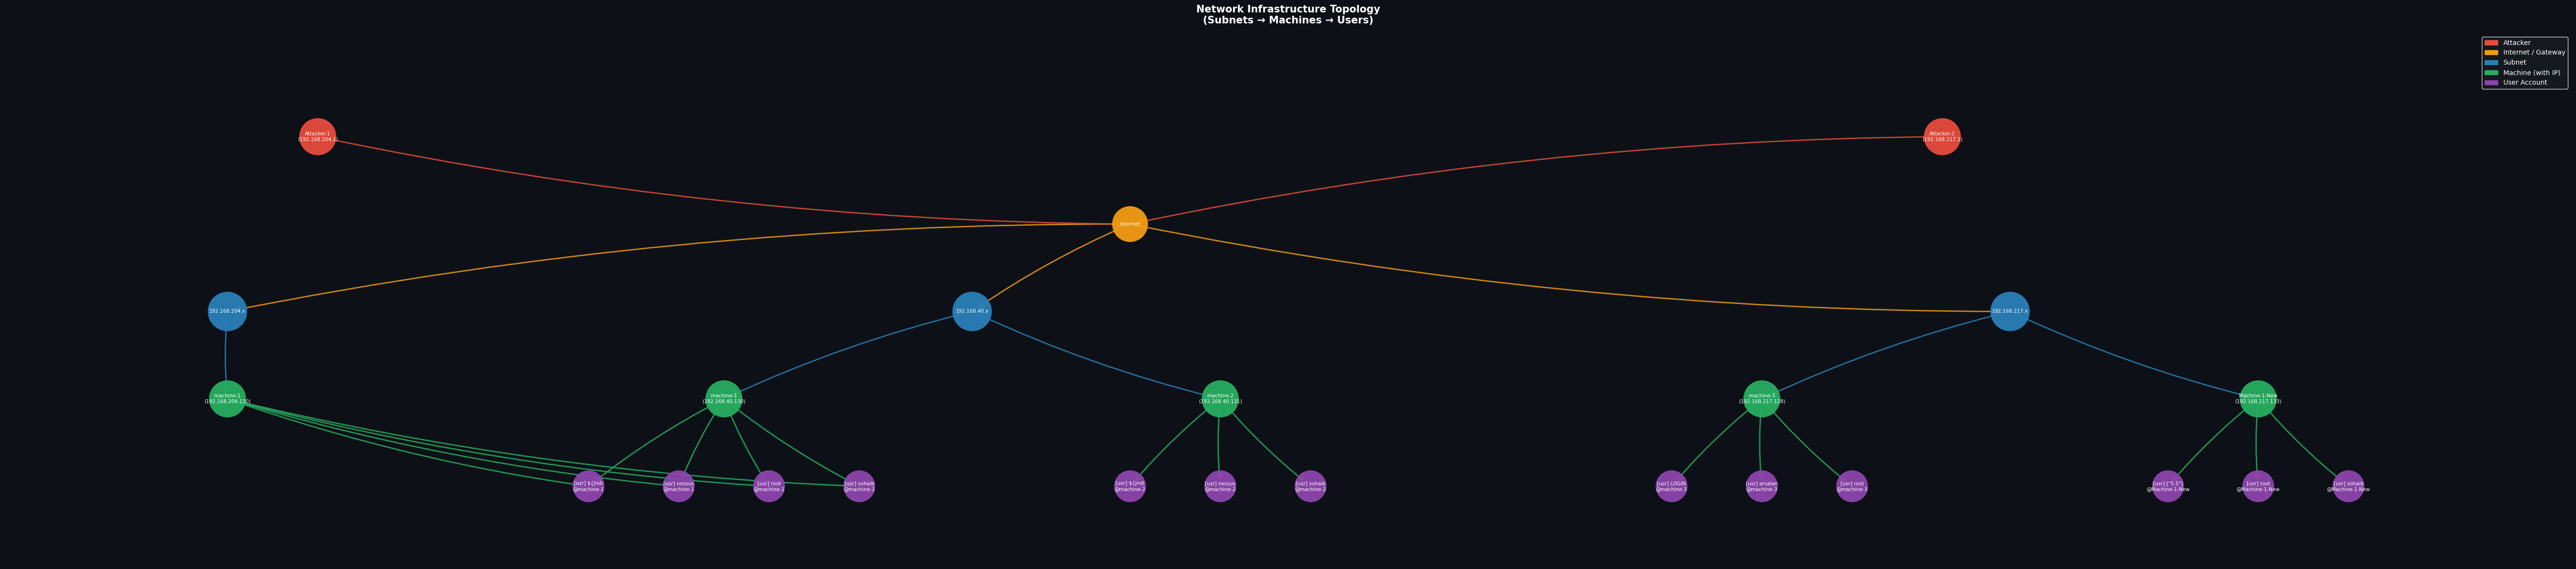

✅ Graph 1 saved → graph1_network_topology.png


In [33]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# ─────────────────────────────────────────────
# 1.  Extract real users per agent from df
# ─────────────────────────────────────────────
user_col = None
for candidate in ['_source.data.srcuser', '_source.data.dstuser', '_source.syscheck.uname_after',
                  '_source.data.audit.auid']:
    if candidate in df.columns:
        user_col = candidate
        break

agent_name_col = '_source.agent.name'
agent_ip_col   = '_source.agent.ip'

users_per_agent = {}
if user_col:
    for agent, grp in df.groupby(agent_name_col):
        raw = grp[user_col].dropna().unique().tolist()
        clean = sorted({str(u).strip() for u in raw
                        if str(u).strip() not in ('', 'nan', '-', '0', 'unknown')
                        and len(str(u).strip()) < 20
                        and not str(u).strip().isdigit()
                        })[:5]   # cap at 5 per machine
        users_per_agent[agent] = clean if clean else ['(no user)']
else:
    for agent in df[agent_name_col].dropna().unique():
        users_per_agent[agent] = ['(no user)']

# ─────────────────────────────────────────────
# 2.  Hard-coded topology
# ─────────────────────────────────────────────
subnets = {
    '192.168.204.x': {'machine-1':      ['192.168.204.130']},
    '192.168.40.x':  {'machine-1':      ['192.168.40.130'],
                      'machine-2':      ['192.168.40.131']},
    '192.168.217.x': {'machine-3':      ['192.168.217.128'],
                      'Machine-1-New':  ['192.168.217.133']},
}

attackers = {
    'Attacker-1': '192.168.204.1',
    'Attacker-2': '192.168.217.1',
}

# ─────────────────────────────────────────────
# 3.  Build graph
# ─────────────────────────────────────────────
G = nx.DiGraph()
attacker_nodes = []
subnet_nodes   = []
machine_nodes  = []
user_nodes     = []

internet_node = 'Internet'
G.add_node(internet_node)

for aname, aip in attackers.items():
    lbl = f"{aname}\n({aip})"
    G.add_node(lbl)
    G.add_edge(lbl, internet_node)
    attacker_nodes.append(lbl)

for subnet, machines in subnets.items():
    G.add_node(subnet)
    G.add_edge(internet_node, subnet)
    subnet_nodes.append(subnet)
    for mname, ips in machines.items():
        mnode = f"{mname}\n({ips[0]})"
        G.add_node(mnode)
        G.add_edge(subnet, mnode)
        machine_nodes.append(mnode)
        for u in users_per_agent.get(mname, ['(no user)']):
            unode = f"[usr] {u}\n@{mname}"
            G.add_node(unode)
            G.add_edge(mnode, unode)
            user_nodes.append(unode)

# ─────────────────────────────────────────────
# 4.  Explicit positions – wide canvas
#     Machine centres chosen so user clouds never overlap
#     (5 users × gap 2.0 = 8-unit cloud per machine;
#      machine centres are ≥ 10 units apart)
# ─────────────────────────────────────────────
pos = {}

# Y levels (well separated vertically)
Y_ATK  = 6.0
Y_INET = 4.5
Y_SUB  = 3.0
Y_MACH = 1.5
Y_USER = 0.0

# Explicit machine centre x-positions
mach_cx = {
    'machine-1\n(192.168.204.130)': 4,
    'machine-1\n(192.168.40.130)':  15,
    'machine-2\n(192.168.40.131)':  26,
    'machine-3\n(192.168.217.128)': 38,
    'Machine-1-New\n(192.168.217.133)': 49,
}
for mnode, cx in mach_cx.items():
    pos[mnode] = (cx, Y_MACH)

# Subnet centres = centroid of their machines
pos['192.168.204.x'] = (4,    Y_SUB)
pos['192.168.40.x']  = (20.5, Y_SUB)
pos['192.168.217.x'] = (43.5, Y_SUB)

# Internet = horizontal centre of all subnets
pos[internet_node] = (24, Y_INET)

# Attackers
pos['Attacker-1\n(192.168.204.1)'] = (6,  Y_ATK)
pos['Attacker-2\n(192.168.217.1)'] = (42, Y_ATK)

# Users – spread under their machine with a gap of 2.0
USER_GAP = 2.0
for mnode in machine_nodes:
    mname = mnode.split('\n')[0]
    ulabels = [f"[usr] {u}\n@{mname}" for u in users_per_agent.get(mname, ['(no user)'])]
    cx = pos[mnode][0]
    span_start = cx - (len(ulabels) - 1) * USER_GAP / 2
    for k, ul in enumerate(ulabels):
        pos[ul] = (span_start + k * USER_GAP, Y_USER)

# ─────────────────────────────────────────────
# 5.  Draw
# ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(54, 12))
ax.set_facecolor('#0d1117')
fig.patch.set_facecolor('#0d1117')

node_colors, node_sizes = [], []
for n in G.nodes():
    if n in attacker_nodes:
        node_colors.append('#e74c3c'); node_sizes.append(3000)
    elif n == internet_node:
        node_colors.append('#f39c12'); node_sizes.append(2800)
    elif n in subnet_nodes:
        node_colors.append('#2980b9'); node_sizes.append(3400)
    elif n in machine_nodes:
        node_colors.append('#27ae60'); node_sizes.append(3000)
    else:
        node_colors.append('#8e44ad'); node_sizes.append(2200)

edge_colors = []
for u, v in G.edges():
    if u in attacker_nodes:      edge_colors.append('#e74c3c')
    elif u == internet_node:     edge_colors.append('#f39c12')
    elif u in subnet_nodes:      edge_colors.append('#2980b9')
    else:                        edge_colors.append('#27ae60')

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, ax=ax, alpha=0.95)
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, arrows=True,
                       arrowsize=20, width=2.0, ax=ax,
                       connectionstyle='arc3,rad=0.05', alpha=0.85)
nx.draw_networkx_labels(G, pos, font_size=7.5, font_color='white', ax=ax)

legend_elements = [
    mpatches.Patch(color='#e74c3c', label='Attacker'),
    mpatches.Patch(color='#f39c12', label='Internet / Gateway'),
    mpatches.Patch(color='#2980b9', label='Subnet'),
    mpatches.Patch(color='#27ae60', label='Machine (with IP)'),
    mpatches.Patch(color='#8e44ad', label='User Account'),
]
ax.legend(handles=legend_elements, loc='upper right',
          facecolor='#161b22', edgecolor='white', labelcolor='white', fontsize=10)

ax.set_title('Network Infrastructure Topology\n(Subnets → Machines → Users)',
             color='white', fontsize=15, fontweight='bold', pad=15)
ax.axis('off')
plt.tight_layout()
plt.savefig('graph1_network_topology.png', dpi=130, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("✅ Graph 1 saved → graph1_network_topology.png")

## Graph 2: Attack Scenario (APT Kill-Chain in the Dataset)

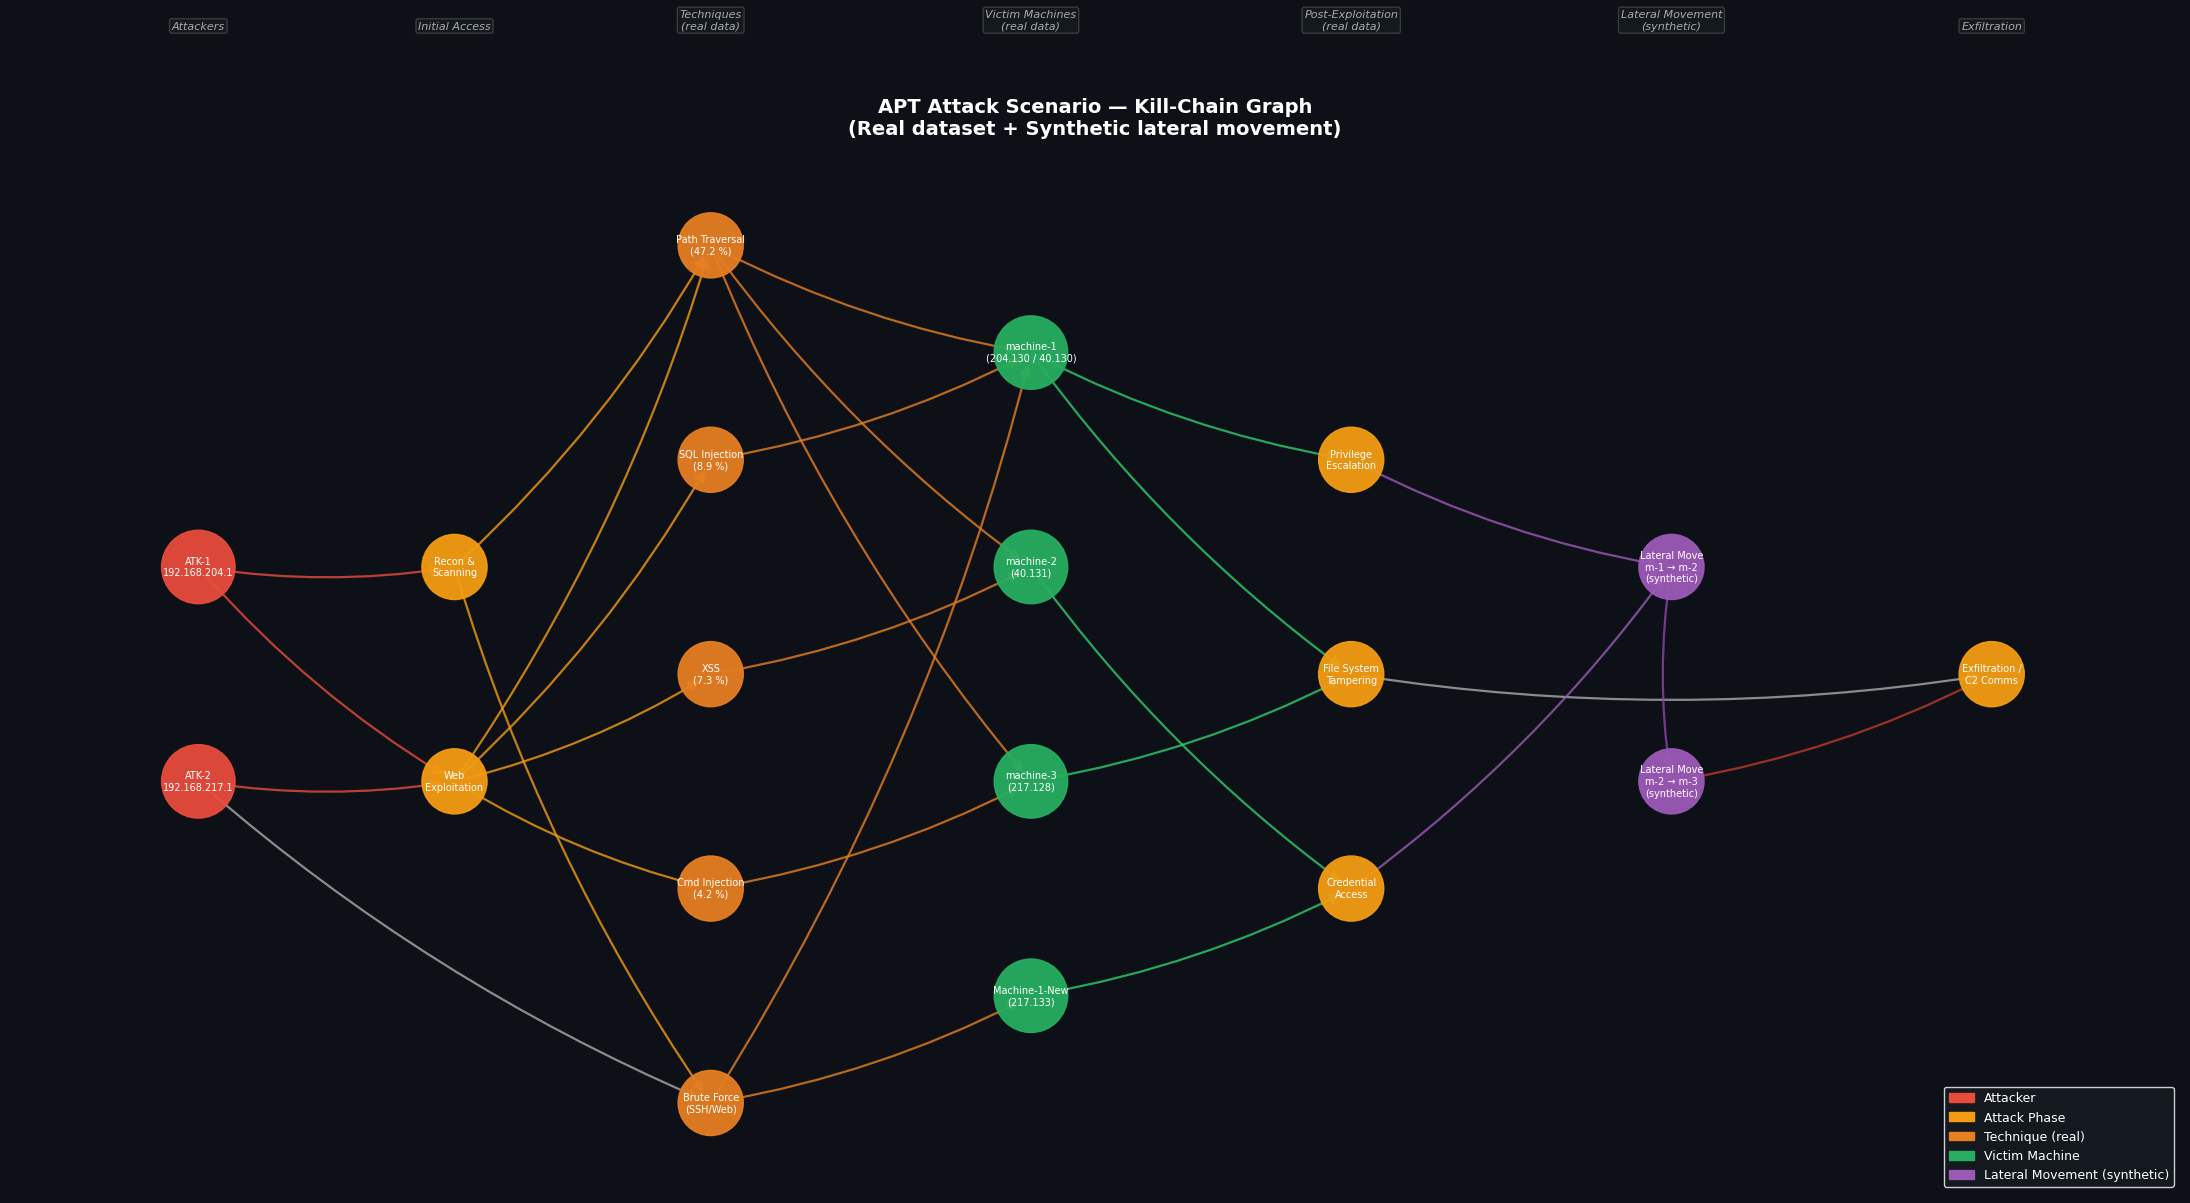

✅ Graph 2 saved → graph2_attack_scenario.png


In [32]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ─────────────────────────────────────────────────────────────────
# Attack scenario graph: APT kill-chain observed in the dataset
#   Real data  : multi-vector web exploitation (star topology)
#   Synthetic  : lateral movement  machine-1 → machine-2 → machine-3
# ─────────────────────────────────────────────────────────────────

G2 = nx.DiGraph()

# ── Nodes ─────────────────────────────────────────────────────────
nodes = {
    # Actors
    'ATK-1\n192.168.204.1':   {'layer': 0, 'kind': 'attacker'},
    'ATK-2\n192.168.217.1':   {'layer': 0, 'kind': 'attacker'},

    # Phase 1 – Initial Access / Reconnaissance (real)
    'Recon &\nScanning':       {'layer': 1, 'kind': 'phase'},
    'Web\nExploitation':        {'layer': 1, 'kind': 'phase'},

    # Techniques (real)
    'Path Traversal\n(47.2 %)':      {'layer': 2, 'kind': 'technique'},
    'SQL Injection\n(8.9 %)':        {'layer': 2, 'kind': 'technique'},
    'XSS\n(7.3 %)':                  {'layer': 2, 'kind': 'technique'},
    'Cmd Injection\n(4.2 %)':        {'layer': 2, 'kind': 'technique'},
    'Brute Force\n(SSH/Web)':         {'layer': 2, 'kind': 'technique'},

    # Victims reached directly (real)
    'machine-1\n(204.130 / 40.130)': {'layer': 3, 'kind': 'victim'},
    'machine-2\n(40.131)':           {'layer': 3, 'kind': 'victim'},
    'machine-3\n(217.128)':          {'layer': 3, 'kind': 'victim'},
    'Machine-1-New\n(217.133)':      {'layer': 3, 'kind': 'victim'},

    # Phase 2 – Post-Exploitation / Persistence (real syscalls)
    'Privilege\nEscalation':    {'layer': 4, 'kind': 'phase'},
    'File System\nTampering':   {'layer': 4, 'kind': 'phase'},
    'Credential\nAccess':       {'layer': 4, 'kind': 'phase'},

    # Lateral movement (SYNTHETIC)
    'Lateral Move\nm-1 → m-2\n(synthetic)': {'layer': 5, 'kind': 'lateral'},
    'Lateral Move\nm-2 → m-3\n(synthetic)': {'layer': 5, 'kind': 'lateral'},

    # Phase 3 – Exfiltration (synthetic + real intent)
    'Exfiltration /\nC2 Comms':  {'layer': 6, 'kind': 'phase'},
}

for n, attr in nodes.items():
    G2.add_node(n, **attr)

# ── Edges ──────────────────────────────────────────────────────────
edges = [
    # Attackers → recon & web exploitation
    ('ATK-1\n192.168.204.1', 'Recon &\nScanning'),
    ('ATK-1\n192.168.204.1', 'Web\nExploitation'),
    ('ATK-2\n192.168.217.1', 'Web\nExploitation'),
    ('ATK-2\n192.168.217.1', 'Brute Force\n(SSH/Web)'),

    # Recon → techniques
    ('Recon &\nScanning',   'Path Traversal\n(47.2 %)'),
    ('Web\nExploitation',   'Path Traversal\n(47.2 %)'),
    ('Web\nExploitation',   'SQL Injection\n(8.9 %)'),
    ('Web\nExploitation',   'XSS\n(7.3 %)'),
    ('Web\nExploitation',   'Cmd Injection\n(4.2 %)'),
    ('Recon &\nScanning',   'Brute Force\n(SSH/Web)'),

    # Techniques → victims (star topology – all attackers hit all machines)
    ('Path Traversal\n(47.2 %)', 'machine-1\n(204.130 / 40.130)'),
    ('Path Traversal\n(47.2 %)', 'machine-2\n(40.131)'),
    ('Path Traversal\n(47.2 %)', 'machine-3\n(217.128)'),
    ('SQL Injection\n(8.9 %)',   'machine-1\n(204.130 / 40.130)'),
    ('XSS\n(7.3 %)',             'machine-2\n(40.131)'),
    ('Cmd Injection\n(4.2 %)',   'machine-3\n(217.128)'),
    ('Brute Force\n(SSH/Web)',   'machine-1\n(204.130 / 40.130)'),
    ('Brute Force\n(SSH/Web)',   'Machine-1-New\n(217.133)'),

    # Victims → post-exploitation
    ('machine-1\n(204.130 / 40.130)', 'Privilege\nEscalation'),
    ('machine-1\n(204.130 / 40.130)', 'File System\nTampering'),
    ('machine-2\n(40.131)',           'Credential\nAccess'),
    ('machine-3\n(217.128)',          'File System\nTampering'),
    ('Machine-1-New\n(217.133)',      'Credential\nAccess'),

    # Post-exploitation → lateral movement (synthetic)
    ('Privilege\nEscalation',  'Lateral Move\nm-1 → m-2\n(synthetic)'),
    ('Credential\nAccess',     'Lateral Move\nm-1 → m-2\n(synthetic)'),
    ('Lateral Move\nm-1 → m-2\n(synthetic)', 'Lateral Move\nm-2 → m-3\n(synthetic)'),

    # Lateral movement → exfiltration
    ('Lateral Move\nm-2 → m-3\n(synthetic)', 'Exfiltration /\nC2 Comms'),
    ('File System\nTampering', 'Exfiltration /\nC2 Comms'),
]
G2.add_edges_from(edges)

# ── Manual positions (layer = x-axis,  spread nodes on y-axis) ─────
layer_x = {0: 0, 1: 2, 2: 4, 3: 6.5, 4: 9, 5: 11.5, 6: 14}

layer_nodes = {}
for n, attr in nodes.items():
    layer_nodes.setdefault(attr['layer'], []).append(n)

pos2 = {}
for layer, nlist in layer_nodes.items():
    total = len(nlist)
    for i, n in enumerate(nlist):
        y = (total - 1) / 2 - i
        pos2[n] = (layer_x[layer], y * 1.5)

# ── Colors ─────────────────────────────────────────────────────────
kind_color = {
    'attacker':  '#e74c3c',
    'phase':     '#f39c12',
    'technique': '#e67e22',
    'victim':    '#27ae60',
    'lateral':   '#9b59b6',
}
node_color_list = [kind_color[G2.nodes[n]['kind']] for n in G2.nodes()]
node_size_list  = [2800 if G2.nodes[n]['kind'] in ('attacker','victim') else 2200
                   for n in G2.nodes()]

edge_color_map = {
    ('attacker','phase'):     '#e74c3c',
    ('phase','technique'):    '#f39c12',
    ('technique','victim'):   '#e67e22',
    ('victim','phase'):       '#2ecc71',
    ('phase','lateral'):      '#9b59b6',
    ('lateral','lateral'):    '#8e44ad',
    ('lateral','phase'):      '#c0392b',
}
edge_colors2 = []
for u, v in G2.edges():
    ku = G2.nodes[u]['kind']
    kv = G2.nodes[v]['kind']
    edge_colors2.append(edge_color_map.get((ku, kv), '#aaaaaa'))

# ── Draw ────────────────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(22, 12))
ax2.set_facecolor('#0d1117')
fig2.patch.set_facecolor('#0d1117')

nx.draw_networkx_nodes(G2, pos2, node_color=node_color_list,
                       node_size=node_size_list, ax=ax2, alpha=0.95)
nx.draw_networkx_edges(G2, pos2, edge_color=edge_colors2, arrows=True,
                       arrowsize=16, width=1.6, ax=ax2,
                       connectionstyle='arc3,rad=0.08', alpha=0.80)
nx.draw_networkx_labels(G2, pos2, font_size=7, font_color='white', ax=ax2)

# ── Layer labels ────────────────────────────────────────────────────
layer_labels = {
    0: 'Attackers',
    1: 'Initial Access',
    2: 'Techniques\n(real data)',
    3: 'Victim Machines\n(real data)',
    4: 'Post-Exploitation\n(real data)',
    5: 'Lateral Movement\n(synthetic)',
    6: 'Exfiltration',
}
for layer, lbl in layer_labels.items():
    ax2.text(layer_x[layer], 4.5, lbl, ha='center', va='bottom',
             color='#aaaaaa', fontsize=8, style='italic',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='#161b22',
                       edgecolor='#444', alpha=0.8))

legend_el = [
    mpatches.Patch(color='#e74c3c', label='Attacker'),
    mpatches.Patch(color='#f39c12', label='Attack Phase'),
    mpatches.Patch(color='#e67e22', label='Technique (real)'),
    mpatches.Patch(color='#27ae60', label='Victim Machine'),
    mpatches.Patch(color='#9b59b6', label='Lateral Movement (synthetic)'),
]
ax2.legend(handles=legend_el, loc='lower right',
           facecolor='#161b22', edgecolor='white', labelcolor='white', fontsize=9)

ax2.set_title('APT Attack Scenario — Kill-Chain Graph\n'
              '(Real dataset + Synthetic lateral movement)',
              color='white', fontsize=14, fontweight='bold', pad=15)
ax2.axis('off')
plt.tight_layout()
plt.savefig('graph2_attack_scenario.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("✅ Graph 2 saved → graph2_attack_scenario.png")